# VPN Threat Detection
## 01 - Data Exploration

Objective:
To understand the structure, features, labels, and quality
of the datasets used for encrypted traffic threat detection.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [14]:
PROJECT_ROOT = Path(r"D:\Projects\VPN_Threat_Detection")

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

print("Project:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_DIR)
print("Processed data:", PROCESSED_DATA_DIR)

Project: D:\Projects\VPN_Threat_Detection
Raw data: D:\Projects\VPN_Threat_Detection\data\raw
Processed data: D:\Projects\VPN_Threat_Detection\data\processed


In [15]:
print("Current notebook directory:")
print(Path.cwd())

print("\nCurrent directory contents:")
for item in Path.cwd().iterdir():
    print(item)

Current notebook directory:
d:\college docs\Final Year Project\VPN_Threat_Detection\notebooks

Current directory contents:
d:\college docs\Final Year Project\VPN_Threat_Detection\notebooks\01_data_processing.ipynb


In [16]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "Datasets"

print("Project:", PROJECT_ROOT)
print("Dataset folder exists:", DATA_DIR.exists())

Project: d:\college docs\Final Year Project\VPN_Threat_Detection\notebooks
Dataset folder exists: False


In [17]:
for file in DATA_DIR.rglob("*"):
    if file.is_file():
        print(file.name)
        print("Size:", round(file.stat().st_size / (1024**2), 2), "MB")
        print("-" * 40)

In [19]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\college docs\Final Year Project\VPN_Threat_Detection")

DATA_DIR = PROJECT_DIR / "Datasets"

print("Dataset directory:", DATA_DIR)
print("Folder exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for file in DATA_DIR.iterdir():
        print(file.name)

Dataset directory: D:\college docs\Final Year Project\VPN_Threat_Detection\Datasets
Folder exists: True
encrypted_vpn_dataset
malware.parquet


In [20]:
VPN_DATA = DATA_DIR / "encrypted_vpn_dataset"

print("VPN dataset folder exists:", VPN_DATA.exists())

for file in VPN_DATA.rglob("*"):
    if file.is_file():
        print(file.name)
        print("Size:", round(file.stat().st_size / (1024**2), 2), "MB")
        print("-" * 40)

VPN dataset folder exists: True
mail.json
Size: 0.88 MB
----------------------------------------
meet.json
Size: 10.04 MB
----------------------------------------
non_streaming.json
Size: 3880.16 MB
----------------------------------------
ssh.json
Size: 2.81 MB
----------------------------------------
streaming.json
Size: 467.14 MB
----------------------------------------
mail.json
Size: 0.01 MB
----------------------------------------
meet.json
Size: 5.41 MB
----------------------------------------
non_streaming.json
Size: 1485.53 MB
----------------------------------------
ssh.json
Size: 0.03 MB
----------------------------------------
streaming.json
Size: 200.26 MB
----------------------------------------
mail.json
Size: 0.21 MB
----------------------------------------
meet.json
Size: 15.66 MB
----------------------------------------
non_streaming.json
Size: 2352.7 MB
----------------------------------------
ssh.json
Size: 0.04 MB
----------------------------------------
streaming.

In [22]:
small_json = min(
    (f for f in VPN_DATA.rglob("*.json") if f.is_file()),
    key=lambda f: f.stat().st_size
)

print("Smallest JSON:", small_json)
print("Size in MB:", round(small_json.stat().st_size / (1024**2), 2))

Smallest JSON: D:\college docs\Final Year Project\VPN_Threat_Detection\Datasets\encrypted_vpn_dataset\VPN\L2TP\mail.json
Size in MB: 0.01


In [23]:
# Load a JSON file and inspect its data type, structure, and first record
import json

with open(small_json, "r", encoding="utf-8") as file:
    data = json.load(file)

print("Data type:", type(data))

if isinstance(data, dict):
    print("Keys:", list(data.keys()))

elif isinstance(data, list):
    print("Number of records:", len(data))
    print("First record:")
    print(data[0])

Data type: <class 'list'>
Number of records: 1
First record:
{'ip_proto': 'udp', 'port_dst': 1701, 'port_src': 1701, 'x_packets': [{'bytes': '102', 'ip_header_len': '20', 'packets': '1', 'timestamp_end': '2022-09-20 23:27:40.617884', 'timestamp_start': '2022-09-20 23:27:40.617884'}, {'bytes': '-102', 'ip_header_len': '20', 'packets': '1', 'timestamp_end': '2022-09-20 23:27:40.626706', 'timestamp_start': '2022-09-20 23:27:40.626706'}, {'bytes': '94', 'ip_header_len': '20', 'packets': '1', 'timestamp_end': '2022-09-20 23:27:40.627936', 'timestamp_start': '2022-09-20 23:27:40.627936'}, {'bytes': '-205', 'ip_header_len': '20', 'packets': '1', 'timestamp_end': '2022-09-20 23:27:40.637558', 'timestamp_start': '2022-09-20 23:27:40.637558'}, {'bytes': '94', 'ip_header_len': '20', 'packets': '1', 'timestamp_end': '2022-09-20 23:27:40.638692', 'timestamp_start': '2022-09-20 23:27:40.638692'}, {'bytes': '112', 'ip_header_len': '20', 'packets': '1', 'timestamp_end': '2022-09-20 23:27:40.639261', '

In [24]:
# Inspect the first network flow record, its metadata, and its first three packet observations
record = data[0]

print("Record fields:", record.keys())

print("\nProtocol:", record["ip_proto"])
print("Source port:", record["port_src"])
print("Destination port:", record["port_dst"])

packets = record["x_packets"]

print("\nNumber of packets:", len(packets))
print("\nFirst 3 packets:")
display(pd.DataFrame(packets[:3]))

Record fields: dict_keys(['ip_proto', 'port_dst', 'port_src', 'x_packets'])

Protocol: udp
Source port: 1701
Destination port: 1701

Number of packets: 34

First 3 packets:


,bytes,ip_header_len,packets,timestamp_end,timestamp_start
0,102,20,1,2022-09-20 23:27:40.617884,2022-09-20 23:27:40.617884
1,-102,20,1,2022-09-20 23:27:40.626706,2022-09-20 23:27:40.626706
2,94,20,1,2022-09-20 23:27:40.627936,2022-09-20 23:27:40.627936


In [25]:
def extract_features(record):

    # Convert packet data from the flow record into a DataFrame
    packets = pd.DataFrame(record["x_packets"])

    # Convert byte and packet count columns from strings to numeric values
    packets["bytes"] = pd.to_numeric(packets["bytes"])
    packets["packets"] = pd.to_numeric(packets["packets"])

    # Convert timestamp strings into datetime objects for time calculations
    packets["timestamp_start"] = pd.to_datetime(
        packets["timestamp_start"]
    )

    # Calculate absolute packet sizes, ignoring traffic direction
    packet_sizes = packets["bytes"].abs()

    # Sort packet timestamps chronologically
    timestamps = packets["timestamp_start"].sort_values()

    # Calculate time differences between consecutive packets in seconds
    inter_arrival = timestamps.diff().dt.total_seconds().dropna()

    # Calculate total duration of the network flow in seconds
    duration = (
        packets["timestamp_start"].max()
        - packets["timestamp_start"].min()
    ).total_seconds()

    # Create a dictionary containing extracted network traffic features
    features = {
        # Extract protocol and source/destination port information
        "protocol": record["ip_proto"],
        "src_port": record["port_src"],
        "dst_port": record["port_dst"],

        # Calculate total packet count and total bytes transferred
        "total_packets": packets["packets"].sum(),
        "total_bytes": packet_sizes.sum(),

        # Calculate bytes transferred in positive and negative directions
        "positive_bytes": packets.loc[
            packets["bytes"] > 0, "bytes"
        ].sum(),

        "negative_bytes": packets.loc[
            packets["bytes"] < 0, "bytes"
        ].abs().sum(),

        # Calculate average and standard deviation of packet sizes
        "mean_packet_size": packet_sizes.mean(),
        "std_packet_size": packet_sizes.std(),

        # Store total traffic duration
        "duration": duration,

        # Calculate average and variability of packet arrival intervals
        "mean_inter_arrival": inter_arrival.mean(),
        "std_inter_arrival": inter_arrival.std()
    }

    # Return the extracted features for further processing or ML
    return features

In [26]:
sample_features = extract_features(data[0])

print(sample_features)

{'protocol': 'udp', 'src_port': 1701, 'dst_port': 1701, 'total_packets': np.int64(34), 'total_bytes': np.int64(9902), 'positive_bytes': np.int64(3472), 'negative_bytes': np.int64(6430), 'mean_packet_size': np.float64(291.2352941176471), 'std_packet_size': np.float64(387.2006807863669), 'duration': 1.088316, 'mean_inter_arrival': np.float64(0.03297927272727273), 'std_inter_arrival': np.float64(0.1305639245698426)}


In [27]:
sample_df = pd.DataFrame([sample_features])

display(sample_df)

,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564


In [28]:
print("Total records:", len(data))

Total records: 1


In [29]:
# Inventory all VPN dataset JSON files with their paths and sizes to understand dataset distribution and identify files for testing
json_files = [
    f for f in VPN_DATA.rglob("*.json")
    if f.is_file()
]

json_info = pd.DataFrame({
    "file": [f.name for f in json_files],
    "path": [str(f) for f in json_files],
    "size_MB": [
        round(f.stat().st_size / (1024**2), 2)
        for f in json_files
    ]
})

display(
    json_info.sort_values("size_MB").reset_index(drop=True)
)

,file,path,size_MB
0,mail.json,D:\college docs\Final Year Project\VPN_Threat_...,0.01
1,ssh.json,D:\college docs\Final Year Project\VPN_Threat_...,0.03
2,ssh.json,D:\college docs\Final Year Project\VPN_Threat_...,0.04
3,ssh.json,D:\college docs\Final Year Project\VPN_Threat_...,0.04
4,ssh.json,D:\college docs\Final Year Project\VPN_Threat_...,0.04
5,ssh.json,D:\college docs\Final Year Project\VPN_Threat_...,0.12
6,ssh.json,D:\college docs\Final Year Project\VPN_Threat_...,0.15
7,mail.json,D:\college docs\Final Year Project\VPN_Threat_...,0.21
8,mail.json,D:\college docs\Final Year Project\VPN_Threat_...,0.23
9,mail.json,D:\college docs\Final Year Project\VPN_Threat_...,0.24


In [30]:
mail_file = json_info[
    (json_info["file"] == "mail.json") &
    (json_info["size_MB"] >= 0.8)
].iloc[0]["path"]

print("Selected file:", mail_file)

Selected file: D:\college docs\Final Year Project\VPN_Threat_Detection\Datasets\encrypted_vpn_dataset\Non VPN\mail.json


In [31]:
with open(mail_file, "r", encoding="utf-8") as file:
    mail_data = json.load(file)

print("Data type:", type(mail_data))
print("Number of records:", len(mail_data))

Data type: <class 'list'>
Number of records: 78


In [32]:
# Extract traffic features from every mail flow record and convert them into a structured DataFrame for ML analysis
mail_features = []

for record in mail_data:
    features = extract_features(record)
    mail_features.append(features)

mail_df = pd.DataFrame(mail_features)

print("Feature dataset shape:", mail_df.shape)
display(mail_df.head())

Feature dataset shape: (78, 12)


,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival
0,udp,52698,9000,178,77840,77840,0,439.774011,82.340444,27.647996,0.157091,0.370055
1,gre,0,0,291,63261,23314,39947,217.391753,306.976318,27.374294,0.094394,0.222756
2,tcp,42048,587,44,8807,2667,6140,200.159091,349.798476,1.150422,0.026754,0.090981
3,tcp,443,32816,4,208,104,104,52.000000,0.000000,15.240373,5.080124,8.797808
4,udp,13231,13231,5,880,880,0,176.000000,0.000000,22.399726,5.599932,0.375248


In [33]:
# Initialize a list to store extracted features from all JSON files
all_features = []

In [34]:

# Summarize JSON file record counts and sizes without printing every file individually

json_summary = []

for file_path in json_files:
    json_summary.append({
        "category": file_path.parent.relative_to(VPN_DATA),
        "file": file_path.name,
        "records": None,
        "size_MB": round(file_path.stat().st_size / (1024**2), 2)
    })

json_summary_df = pd.DataFrame(json_summary)

display(json_summary_df.head(20))
print("Total JSON files:", len(json_files))


,category,file,records,size_MB
0,Non VPN,mail.json,None,0.88
1,Non VPN,meet.json,None,10.04
2,Non VPN,non_streaming.json,None,3880.16
3,Non VPN,ssh.json,None,2.81
4,Non VPN,streaming.json,None,467.14
5,VPN\L2TP,mail.json,None,0.01
6,VPN\L2TP,meet.json,None,5.41
7,VPN\L2TP,non_streaming.json,None,1485.53
8,VPN\L2TP,ssh.json,None,0.03
9,VPN\L2TP,streaming.json,None,200.26


Total JSON files: 35


### Dataset Observations

1. **Application Types:** The dataset contains five application categories: `mail`, `meet`, `non_streaming`, `ssh`, and `streaming`.
2. **Traffic Categories:** It includes multiple VPN protocols and Non-VPN traffic.
3. **Large Files:** Several JSON files exceed 1 GB, requiring incremental processing to manage memory and processing time efficiently.
4. **Metadata Preservation:** We should preserve both `category` (VPN protocol or Non-VPN) and `application` (traffic type) as metadata for every extracted flow.

### Objective: 
#### Build a reusable preprocessing pipeline to convert raw VPN and Non-VPN JSON traffic into an ML-ready feature dataset using feature extraction, metadata assignment, incremental processing, and Parquet storage.

**Step 1 — Create the output directory**:  
We need a place to save the processed feature datasets so we don't have to extract features again tomorrow.

In [35]:
# Create a directory to store processed feature datasets
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data directory:", PROCESSED_DATA_DIR)

Processed data directory: D:\Projects\VPN_Threat_Detection\data\processed


In [36]:
# Select the smallest JSON file to test feature extraction
test_file = min(json_files, key=lambda f: f.stat().st_size)

print("Selected file:", test_file)
print("Size (MB):", round(test_file.stat().st_size / (1024**2), 2))

Selected file: D:\college docs\Final Year Project\VPN_Threat_Detection\Datasets\encrypted_vpn_dataset\VPN\L2TP\mail.json
Size (MB): 0.01


In [37]:
# Load the selected JSON file into Python
with open(test_file, "r", encoding="utf-8") as file:
    test_data = json.load(file)

print("Number of flow records:", len(test_data))
print("First record keys:", test_data[0].keys())

Number of flow records: 1
First record keys: dict_keys(['ip_proto', 'port_dst', 'port_src', 'x_packets'])


In [38]:
# Extract ML features from every network flow record in the selected file
test_features = []

for record in test_data:
    features = extract_features(record)
    test_features.append(features)

test_df = pd.DataFrame(test_features)

display(test_df)

,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564


In [39]:
# Add VPN protocol category and application type as metadata
test_df["category"] = test_file.parent.name
test_df["application"] = test_file.stem

display(test_df)

,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival,category,application
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564,L2TP,mail


In [40]:
# Save the extracted features to a Parquet file for reuse
test_output = PROCESSED_DATA_DIR / "L2TP_mail.parquet"

test_df.to_parquet(test_output, index=False)

print("Saved to:", test_output)

Saved to: D:\Projects\VPN_Threat_Detection\data\processed\L2TP_mail.parquet


In [41]:
# Reload the saved Parquet file to verify successful storage
loaded_df = pd.read_parquet(test_output)

display(loaded_df)

,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival,category,application
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564,L2TP,mail


In [42]:
# Install a parser that reads large JSON files incrementally
%pip install ijson

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:

import ijson

print("ijson installed successfully!")


ijson installed successfully!


In [44]:

import ijson
import pyarrow as pa
import pyarrow.parquet as pq


In [45]:

def process_json_file(file_path, batch_size=1000):

    # Identify category and application
    category = file_path.parent.name
    application = file_path.stem

    # Create output folder and temporary file
    output_folder = PROCESSED_DATA_DIR / category.replace(" ", "_")
    output_folder.mkdir(parents=True, exist_ok=True)

    output_path = output_folder / f"{application}.parquet"
    temp_path = output_folder / f"{application}.tmp.parquet"

    # Skip if already processed
    if output_path.exists():
        print(f"Already processed: {output_path.name}")
        return

    features_batch = []
    writer = None
    schema = None
    records_processed = 0

    # Read JSON records one at a time
    with open(file_path, "rb") as file:
        for record in ijson.items(file, "item"):

            # Extract features
            features = extract_features(record)

            # Add labels
            features["category"] = category
            features["application"] = application

            features_batch.append(features)

            # Write batch when it reaches batch_size
            if len(features_batch) >= batch_size:

                batch_df = pd.DataFrame(features_batch)
                table = pa.Table.from_pandas(
                    batch_df,
                    preserve_index=False
                )

                if writer is None:
                    schema = table.schema
                    writer = pq.ParquetWriter(temp_path, schema)
                else:
                    table = table.cast(schema)

                writer.write_table(table)

                records_processed += len(features_batch)
                features_batch.clear()

    # Write remaining records
    if features_batch:

        batch_df = pd.DataFrame(features_batch)
        table = pa.Table.from_pandas(
            batch_df,
            preserve_index=False
        )

        if writer is None:
            schema = table.schema
            writer = pq.ParquetWriter(temp_path, schema)
        else:
            table = table.cast(schema)

        writer.write_table(table)
        records_processed += len(features_batch)

    # Finalize output
    if writer is not None:
        writer.close()
        temp_path.replace(output_path)

    print(f"Processed: {file_path.name}")
    print(f"Records: {records_processed}")
    print(f"Saved: {output_path}")


In [46]:

process_json_file(test_file)


Already processed: mail.parquet


In [47]:

processed_file = PROCESSED_DATA_DIR / "L2TP" / "mail.parquet"

check_df = pd.read_parquet(processed_file)

print("Shape:", check_df.shape)
print("\nColumns:")
print(check_df.columns.tolist())

display(check_df)


Shape: (1, 14)

Columns:
['protocol', 'src_port', 'dst_port', 'total_packets', 'total_bytes', 'positive_bytes', 'negative_bytes', 'mean_packet_size', 'std_packet_size', 'duration', 'mean_inter_arrival', 'std_inter_arrival', 'category', 'application']


,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival,category,application
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564,L2TP,mail


In [48]:

for file_path in json_files:

    print("\nProcessing:", file_path.name)

    process_json_file(file_path)



Processing: mail.json
Already processed: mail.parquet

Processing: meet.json
Already processed: meet.parquet

Processing: non_streaming.json
Already processed: non_streaming.parquet

Processing: ssh.json
Already processed: ssh.parquet

Processing: streaming.json
Already processed: streaming.parquet

Processing: mail.json
Already processed: mail.parquet

Processing: meet.json
Already processed: meet.parquet

Processing: non_streaming.json
Already processed: non_streaming.parquet

Processing: ssh.json
Already processed: ssh.parquet

Processing: streaming.json
Already processed: streaming.parquet

Processing: mail.json
Already processed: mail.parquet

Processing: meet.json
Already processed: meet.parquet

Processing: non_streaming.json
Already processed: non_streaming.parquet

Processing: ssh.json
Already processed: ssh.parquet

Processing: streaming.json
Already processed: streaming.parquet

Processing: mail.json
Already processed: mail.parquet

Processing: meet.json
Already processed: 

Already processed: mail.parquet

Processing: meet.json
Already processed: meet.parquet

Processing: non_streaming.json
Already processed: non_streaming.parquet

Processing: ssh.json
Already processed: ssh.parquet

Processing: streaming.json
Already processed: streaming.parquet


In [49]:

expected_outputs = {
    PROCESSED_DATA_DIR
    / file_path.parent.name.replace(" ", "_")
    / f"{file_path.stem}.parquet"
    for file_path in json_files
}

existing_outputs = [
    path for path in expected_outputs
    if path.exists()
]

missing_outputs = [
    path for path in expected_outputs
    if not path.exists()
]

print("Total JSON files:", len(json_files))
print("Expected Parquet files:", len(expected_outputs))
print("Successfully saved:", len(existing_outputs))
print("Missing:", len(missing_outputs))

if missing_outputs:
    print("\nFiles not processed:")
    for path in missing_outputs:
        print(path)
else:
    print("\nAll expected files exist!")


Total JSON files: 35
Expected Parquet files: 35
Successfully saved: 35
Missing: 0

All expected files exist!


In [50]:

validation_results = []

for file_path in sorted(existing_outputs):

    try:
        parquet_file = pq.ParquetFile(file_path)

        validation_results.append({
            "file": file_path.name,
            "category": file_path.parent.name,
            "records": parquet_file.metadata.num_rows,
            "status": "OK"
        })

    except Exception as e:
        validation_results.append({
            "file": file_path.name,
            "category": file_path.parent.name,
            "records": 0,
            "status": str(e)
        })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nTotal extracted flow records:",
      validation_df["records"].sum())

print("Invalid files:",
      (validation_df["status"] != "OK").sum())


,file,category,records,status
0,mail.parquet,L2TP,1,OK
1,meet.parquet,L2TP,2,OK
2,non_streaming.parquet,L2TP,1194,OK
3,ssh.parquet,L2TP,5,OK
4,streaming.parquet,L2TP,112,OK
5,mail.parquet,L2TP_IPsec,5,OK
6,meet.parquet,L2TP_IPsec,4,OK
7,non_streaming.parquet,L2TP_IPsec,1759,OK
8,ssh.parquet,L2TP_IPsec,5,OK
9,streaming.parquet,L2TP_IPsec,182,OK



Total extracted flow records: 58977
Invalid files: 0


**Combine all processed files**:
We'll create one master dataset containing all extracted features and metadata.

In [51]:

# Load all processed Parquet files
all_dfs = [
    pd.read_parquet(file_path)
    for file_path in sorted(existing_outputs)
]

# Combine into one DataFrame
vpn_features = pd.concat(all_dfs, ignore_index=True)

# Save master dataset
master_path = PROCESSED_DATA_DIR / "vpn_features.parquet"
vpn_features.to_parquet(master_path, index=False)

print("Master dataset shape:", vpn_features.shape)
print("Saved to:", master_path)

display(vpn_features.head())


Master dataset shape: (58977, 14)
Saved to: D:\Projects\VPN_Threat_Detection\data\processed\vpn_features.parquet


,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival,category,application
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564,L2TP,mail
1,udp,1701,1701,20862,17077194,16125804,951390,852.580829,693.495688,132.964180,0.006639,0.022337,L2TP,meet
2,udp,1701,1701,8633,9954818,228006,9726812,1228.383268,681.626250,7.476910,0.000923,0.027435,L2TP,meet
3,udp,1701,1701,17998,20666541,512145,20154396,1268.041539,846.430639,15.029199,0.000922,0.016929,L2TP,non_streaming
4,udp,1701,1701,27605,32680280,581566,32098714,1242.643447,707.900057,14.033060,0.000534,0.008798,L2TP,non_streaming


In [52]:

# Distribution by VPN protocol/category
print("Traffic category distribution:")
display(vpn_features["category"].value_counts())

# Distribution by application
print("\nApplication distribution:")
display(vpn_features["application"].value_counts())

# Missing values
print("\nMissing values:")
display(vpn_features.isnull().sum())

# Numerical feature statistics
print("\nFeature statistics:")
display(vpn_features.describe().round(2))


Traffic category distribution:


category
Non VPN       50191
L2TP IPsec     1955
WireGuard      1758
PPTP           1521
L2TP           1314
OpenVPN        1120
SSTP           1118
Name: count, dtype: int64


Application distribution:


application
non_streaming    54079
streaming         4631
mail               107
meet                87
ssh                 73
Name: count, dtype: int64


Missing values:


protocol                 0
src_port                 0
dst_port                 0
total_packets            0
total_bytes              0
positive_bytes           0
negative_bytes           0
mean_packet_size         0
std_packet_size       3052
duration                 0
mean_inter_arrival    3052
std_inter_arrival     6273
category                 0
application              0
dtype: int64


Feature statistics:


,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival
count,58977.00,58977.00,58977.0,5.897700e+04,5.897700e+04,5.897700e+04,58977.00,55925.00,58977.00,55925.00,52704.00
mean,35127.30,5374.70,1532.2,1.653086e+06,5.606455e+05,1.092441e+06,604.88,651.61,4.96,0.26,0.19
std,20836.06,12565.37,4324.2,4.754444e+06,2.694164e+06,3.896915e+06,477.41,460.58,22.10,3.56,1.31
min,0.00,0.00,1.0,2.800000e+01,2.800000e+01,0.000000e+00,28.00,0.00,0.00,0.00,0.00
25%,13231.00,443.00,14.0,6.593000e+03,1.039000e+03,4.177000e+03,330.54,498.27,0.04,0.00,0.00
50%,42296.00,443.00,28.0,1.022000e+04,2.724000e+03,6.776000e+03,480.20,589.15,0.16,0.00,0.02
75%,51491.00,2048.00,137.0,1.148940e+05,8.447000e+03,5.443900e+04,763.34,736.00,3.79,0.01,0.05
max,65505.00,65383.00,112130.0,1.575639e+08,1.536062e+08,1.377228e+08,3256.30,4734.60,836.87,300.23,87.72


In [53]:
# Check duplicate records
print("Total duplicate rows:", vpn_features.duplicated().sum())

# Check duplicate rows excluding labels
feature_columns = vpn_features.drop(
    columns=["category", "application"]
)

print(
    "Duplicate feature rows:",
    feature_columns.duplicated().sum()
)

Total duplicate rows: 3664
Duplicate feature rows: 3714


In [54]:
# Feature columns excluding labels
feature_columns = vpn_features.drop(
    columns=["category", "application"]
).columns.tolist()

# Group identical feature combinations
duplicate_groups = (
    vpn_features.groupby(feature_columns, dropna=False)
    .agg(
        category_count=("category", "nunique"),
        application_count=("application", "nunique"),
        total_records=("category", "size")
    )
    .reset_index()
)

# Groups having conflicting categories or applications
conflicting_groups = duplicate_groups[
    (duplicate_groups["category_count"] > 1) |
    (duplicate_groups["application_count"] > 1)
]

print("Conflicting feature groups:", len(conflicting_groups))

display(
    conflicting_groups.sort_values(
        "total_records", ascending=False
    ).head(10)
)

Conflicting feature groups: 39


,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival,category_count,application_count,total_records
0,gre,0,0,1,28,28,0,28.0,NaN,0.000000,NaN,NaN,1,2,794
2368,icmp,0,0,1,36,36,0,36.0,NaN,0.000000,NaN,NaN,1,2,783
2482,icmp,0,2048,1,36,36,0,36.0,NaN,0.000000,NaN,NaN,1,2,783
2515,icmp,0,2817,1,576,576,0,576.0,NaN,0.000000,NaN,NaN,3,2,192
2523,icmp,0,2817,2,1152,1152,0,576.0,0.0,0.000011,0.000011,NaN,2,2,18
2415,icmp,0,771,1,106,106,0,106.0,NaN,0.000000,NaN,NaN,1,2,18
2525,icmp,0,2817,2,1152,1152,0,576.0,0.0,0.000013,0.000013,NaN,3,2,12
2524,icmp,0,2817,2,1152,1152,0,576.0,0.0,0.000012,0.000012,NaN,2,2,11
2518,icmp,0,2817,2,1152,1152,0,576.0,0.0,0.000003,0.000003,NaN,2,2,10
2526,icmp,0,2817,2,1152,1152,0,576.0,0.0,0.000014,0.000014,NaN,2,1,6


In [55]:
# Inspect category labels
print("Category labels:")
display(vpn_features["category"].value_counts())

# Inspect application labels
print("\nApplication labels:")
display(vpn_features["application"].value_counts())

Category labels:


category
Non VPN       50191
L2TP IPsec     1955
WireGuard      1758
PPTP           1521
L2TP           1314
OpenVPN        1120
SSTP           1118
Name: count, dtype: int64


Application labels:


application
non_streaming    54079
streaming         4631
mail               107
meet                87
ssh                 73
Name: count, dtype: int64

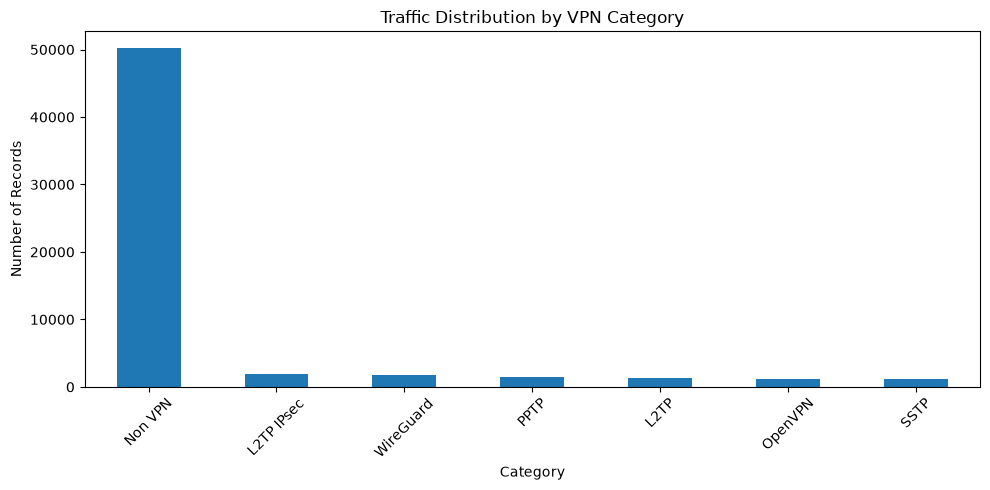

In [56]:
import matplotlib.pyplot as plt

category_counts = vpn_features["category"].value_counts()

plt.figure(figsize=(10, 5))

category_counts.plot(kind="bar")

plt.title("Traffic Distribution by VPN Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

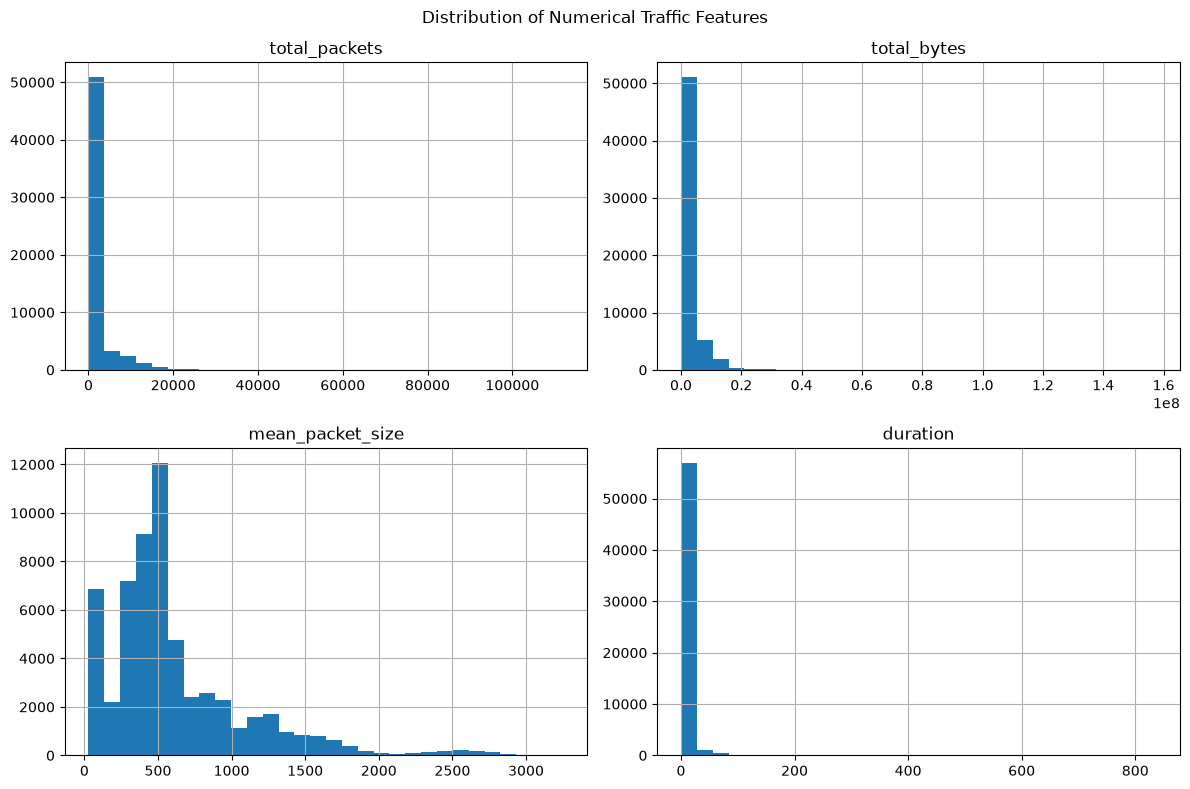

In [57]:
# Select important numerical traffic features
numerical_features = [
    "total_packets",
    "total_bytes",
    "mean_packet_size",
    "duration"
]

# Plot feature distributions
vpn_features[numerical_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.suptitle("Distribution of Numerical Traffic Features")
plt.tight_layout()
plt.show()

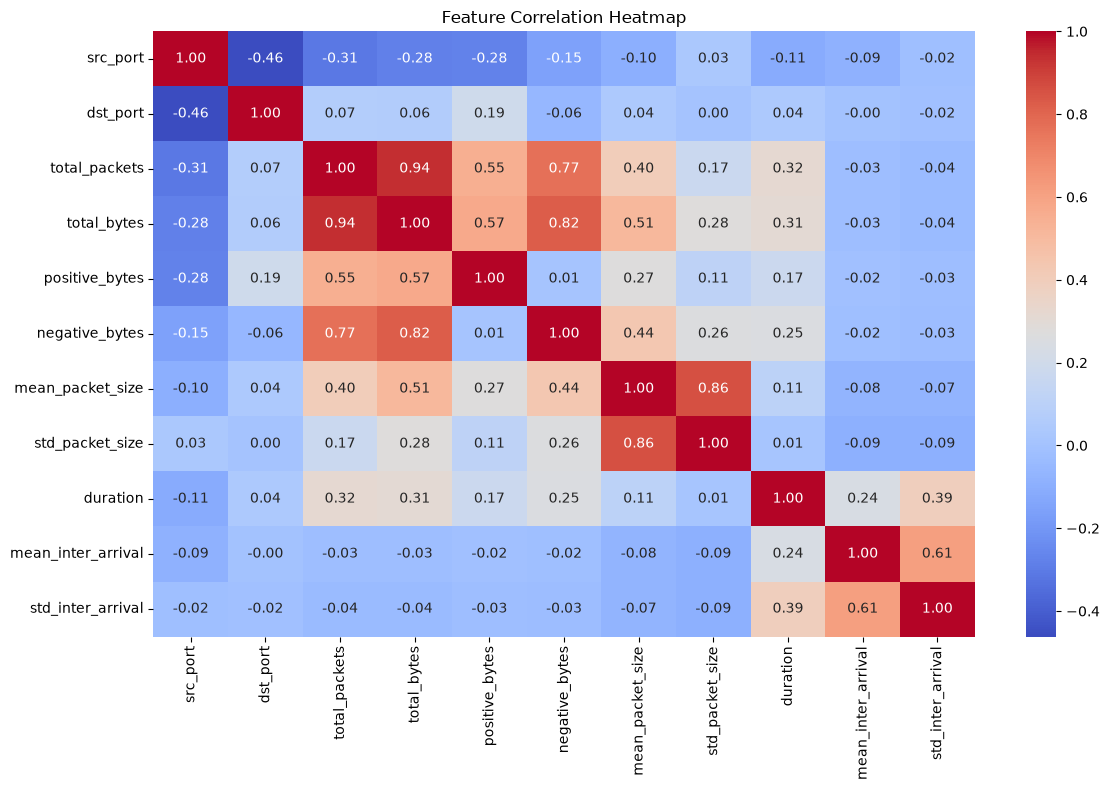

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns only
numerical_data = vpn_features.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

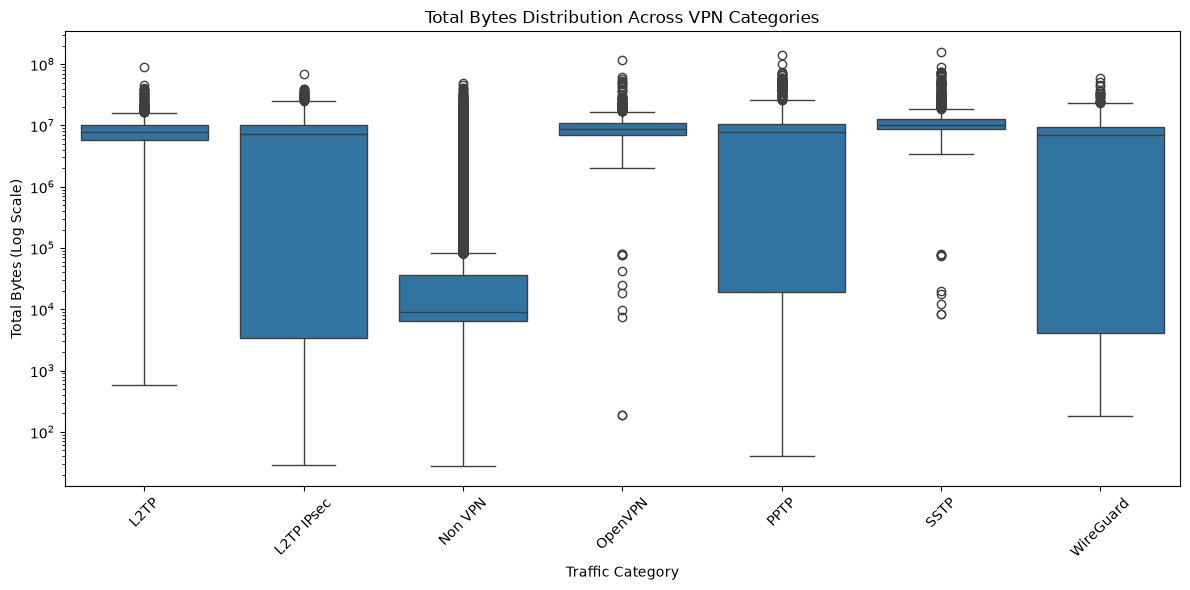

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=vpn_features,
    x="category",
    y="total_bytes"
)

plt.yscale("log")
plt.title("Total Bytes Distribution Across VPN Categories")
plt.xlabel("Traffic Category")
plt.ylabel("Total Bytes (Log Scale)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

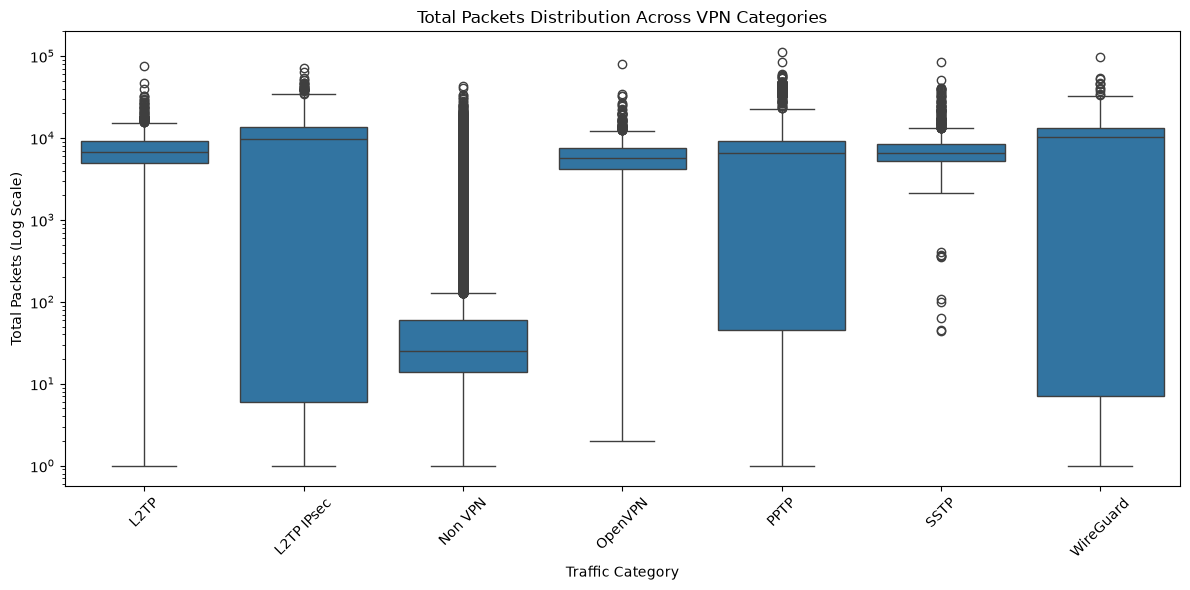

In [60]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=vpn_features,
    x="category",
    y="total_packets"
)

plt.yscale("log")
plt.title("Total Packets Distribution Across VPN Categories")
plt.xlabel("Traffic Category")
plt.ylabel("Total Packets (Log Scale)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [61]:
# Create binary target column
vpn_features["is_vpn"] = (
    vpn_features["category"] != "Non VPN"
).astype(int)

# Check target distribution
print("Binary target distribution:")
display(vpn_features["is_vpn"].value_counts())

# Check proportions
display(
    vpn_features["is_vpn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Binary target distribution:


is_vpn
0    50191
1     8786
Name: count, dtype: int64

is_vpn
0    85.1
1    14.9
Name: proportion, dtype: float64

In [62]:
# Input features (exclude labels)
X = vpn_features.drop(
    columns=["category", "application", "is_vpn"]
)

# Target variable
y = vpn_features["is_vpn"]

# Check shapes
print("X shape:", X.shape)
print("y shape:", y.shape)

# Preview input features
display(X.head())

# Preview target
display(y.head())

X shape: (58977, 12)
y shape: (58977,)


,protocol,src_port,dst_port,total_packets,total_bytes,positive_bytes,negative_bytes,mean_packet_size,std_packet_size,duration,mean_inter_arrival,std_inter_arrival
0,udp,1701,1701,34,9902,3472,6430,291.235294,387.200681,1.088316,0.032979,0.130564
1,udp,1701,1701,20862,17077194,16125804,951390,852.580829,693.495688,132.964180,0.006639,0.022337
2,udp,1701,1701,8633,9954818,228006,9726812,1228.383268,681.626250,7.476910,0.000923,0.027435
3,udp,1701,1701,17998,20666541,512145,20154396,1268.041539,846.430639,15.029199,0.000922,0.016929
4,udp,1701,1701,27605,32680280,581566,32098714,1242.643447,707.900057,14.033060,0.000534,0.008798


0    1
1    1
2    1
3    1
4    1
Name: is_vpn, dtype: int64

In [63]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train distribution:")
display(y_train.value_counts())

print("\ny_test distribution:")
display(y_test.value_counts())

X_train: (47181, 12)
X_test: (11796, 12)

y_train distribution:


is_vpn
0    40152
1     7029
Name: count, dtype: int64


y_test distribution:


is_vpn
0    10039
1     1757
Name: count, dtype: int64

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Separate numerical and categorical columns
categorical_features = ["protocol"]

numerical_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Create complete ML pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [66]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Accuracy: 0.9925398440149203

Classification Report:
              precision    recall  f1-score   support

     Non-VPN       1.00      0.99      1.00     10039
         VPN       0.96      0.99      0.98      1757

    accuracy                           0.99     11796
   macro avg       0.98      0.99      0.99     11796
weighted avg       0.99      0.99      0.99     11796



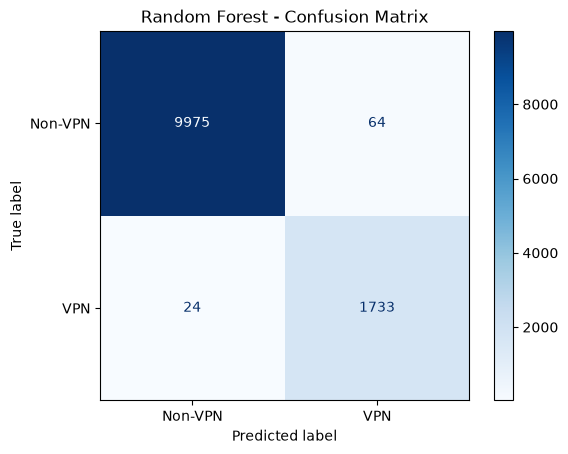

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions
y_pred = rf_model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-VPN", "VPN"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-VPN", "VPN"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [68]:
# Create a unique hash for each feature row
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

# Check overlap
overlap = test_hashes.isin(train_hashes)

print("Test records:", len(X_test))
print("Test records with identical training features:", overlap.sum())

print(
    "Percentage of test records with feature overlap:",
    round(overlap.mean() * 100, 2),
    "%"
)

Test records: 11796
Test records with identical training features: 844
Percentage of test records with feature overlap: 7.15 %


In [69]:
from sklearn.model_selection import GroupShuffleSplit

# Assign a group ID to identical feature rows
groups = pd.util.hash_pandas_object(
    X, index=False
)

# Create group-based split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

# Create new train-test sets
X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

print("Training shape:", X_train_group.shape)
print("Testing shape:", X_test_group.shape)

# Verify no identical feature groups cross the split
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Group overlap:", len(train_groups & test_groups))

Training shape: (47552, 12)
Testing shape: (11425, 12)
Group overlap: 0


Grouped Split Accuracy: 0.9757549234135667

Classification Report:
              precision    recall  f1-score   support

     Non-VPN       0.98      0.99      0.99      9488
         VPN       0.96      0.89      0.93      1937

    accuracy                           0.98     11425
   macro avg       0.97      0.94      0.96     11425
weighted avg       0.98      0.98      0.98     11425



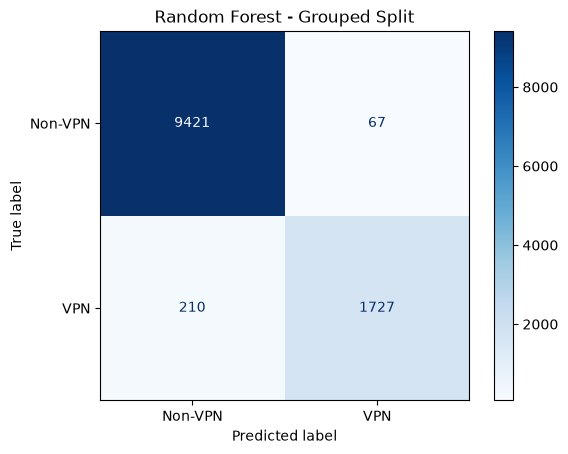

In [70]:
# Train on grouped split
rf_model.fit(X_train_group, y_train_group)

# Predict
y_pred_group = rf_model.predict(X_test_group)

# Evaluate
print("Grouped Split Accuracy:",
      accuracy_score(y_test_group, y_pred_group))

print("\nClassification Report:")
print(classification_report(
    y_test_group,
    y_pred_group,
    target_names=["Non-VPN", "VPN"]
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_group,
    y_pred_group,
    display_labels=["Non-VPN", "VPN"],
    cmap="Blues"
)

plt.title("Random Forest - Grouped Split")
plt.show()

In [71]:
# Get preprocessing and classifier from pipeline
preprocessor = rf_model.named_steps["preprocessor"]
classifier = rf_model.named_steps["classifier"]

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Get feature importance scores
importances = classifier.feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

# Display top 15 features
display(importance_df.head(15))

,feature,importance
2,num__total_packets,0.156915
3,num__total_bytes,0.129821
4,num__positive_bytes,0.125874
6,num__mean_packet_size,0.093515
8,num__duration,0.089831
1,num__dst_port,0.075422
0,num__src_port,0.066726
5,num__negative_bytes,0.061977
7,num__std_packet_size,0.060047
10,num__std_inter_arrival,0.056882


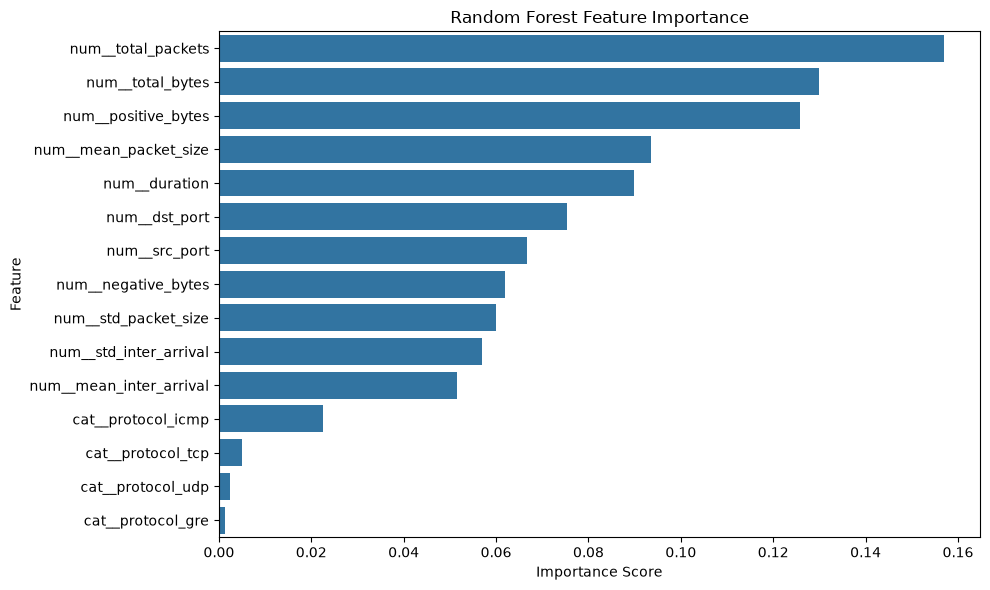

In [72]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# Phase 2: Malware Dataset Exploration

In [73]:
import pandas as pd
from pathlib import Path

# Define dataset path
MALWARE_DATA = Path(
    r"D:\college docs\Final Year Project\VPN_Threat_Detection\Datasets\malware.parquet"
)

# Load dataset
malware_df = pd.read_parquet(MALWARE_DATA)

print("Dataset loaded successfully!")
print("Shape:", malware_df.shape)

# Display first 5 records
display(malware_df.head())

Dataset loaded successfully!
Shape: (1405079, 31)


,bs,ps,br,pr,dp,sp,da,sa,ts,td,...,tls.ja3,tls.ja4,tls.ja3s,tls.ja4s,meta.sample.id,meta.malware.family,meta.system.os,meta.system.service,meta.application.name,tls.rec
0,1262,13,8316,12,443,49792,20.72.205.209,10.127.0.189,1.756762e+09,0.941528,...,28a2c9bd18a11de089ef85a160da29e4,t12d1909h2_d83cc789557e_7af1ed941c26,2fe9b0e731d3d41b2b84e8e1d6186836,t1204h2_c030_5333cdffa7d9,250901-1aw26afr2z_behavioral1,NaN,windows10-2004-x64,microsoft_telemetry,None,"[-211, 3753, -102, -1, -40, 1, 40, 64, -82, -2..."
1,49974,64,39987,54,443,49801,40.126.31.67,10.127.0.189,1.756762e+09,128.561234,...,28a2c9bd18a11de089ef85a160da29e4,t12d1909h2_d83cc789557e_7af1ed941c26,7d8fd34fdb13a7fff30d5a52846b6c4c,t120400_c030_09f674154ab3,250901-1aw26afr2z_behavioral1,NaN,windows10-2004-x64,NaN,None,"[-226, 3954, -102, -1, -40, 1, 40, -445, -3616..."
2,35832,48,31235,40,443,49803,40.126.31.67,10.127.0.189,1.756762e+09,138.264477,...,28a2c9bd18a11de089ef85a160da29e4,t12d1909h2_d83cc789557e_7af1ed941c26,7d8fd34fdb13a7fff30d5a52846b6c4c,t120400_c030_09f674154ab3,250901-1aw26afr2z_behavioral1,NaN,windows10-2004-x64,NaN,None,"[-226, 3954, -102, -1, -40, 1, 40, -469, -7637..."
3,4529,14,8280,14,443,49804,20.72.205.209,10.127.0.189,1.756762e+09,1.195099,...,28a2c9bd18a11de089ef85a160da29e4,t12d1909h2_d83cc789557e_7af1ed941c26,2fe9b0e731d3d41b2b84e8e1d6186836,t1204h2_c030_5333cdffa7d9,250901-1aw26afr2z_behavioral1,NaN,windows10-2004-x64,microsoft_telemetry,None,"[-211, 3753, -102, -1, -40, 1, 40, 64, -82, -1..."
4,4035,14,4910,13,443,49806,52.167.17.97,10.127.0.189,1.756762e+09,0.749950,...,28a2c9bd18a11de089ef85a160da29e4,t12d1909h2_d83cc789557e_7af1ed941c26,2fe9b0e731d3d41b2b84e8e1d6186836,t1204h2_c030_5333cdffa7d9,250901-1aw26afr2z_behavioral1,NaN,windows10-2004-x64,microsoft_telemetry,None,"[-211, 3753, -102, -1, -40, 1, 40, 64, -82, -1..."


In [74]:
# Display column names
print("Columns:")
print(malware_df.columns.tolist())

# Display data types
print("\nData types:")
display(malware_df.dtypes)

# Dataset information
print("\nDataset info:")
malware_df.info()

Columns:
['bs', 'ps', 'br', 'pr', 'dp', 'sp', 'da', 'sa', 'ts', 'td', 'tls.cver', 'tls.sver', 'tls.sext', 'tls.csg', 'tls.ccs', 'tls.cext', 'tls.ssv', 'tls.csv', 'tls.scs', 'tls.alpn', 'tls.sni', 'tls.ja3', 'tls.ja4', 'tls.ja3s', 'tls.ja4s', 'meta.sample.id', 'meta.malware.family', 'meta.system.os', 'meta.system.service', 'meta.application.name', 'tls.rec']

Data types:


bs                         int64
ps                         int64
br                         int64
pr                         int64
dp                         int64
sp                         int64
da                           str
sa                           str
ts                       float64
td                       float64
tls.cver                     str
tls.sver                     str
tls.sext                  object
tls.csg                   object
tls.ccs                   object
tls.cext                  object
tls.ssv                   object
tls.csv                   object
tls.scs                      str
tls.alpn                  object
tls.sni                      str
tls.ja3                      str
tls.ja4                      str
tls.ja3s                     str
tls.ja4s                     str
meta.sample.id               str
meta.malware.family          str
meta.system.os               str
meta.system.service          str
meta.application.name     object
tls.rec   


Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 1405079 entries, 0 to 1405078
Data columns (total 31 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   bs                     1405079 non-null  int64  
 1   ps                     1405079 non-null  int64  
 2   br                     1405079 non-null  int64  
 3   pr                     1405079 non-null  int64  
 4   dp                     1405079 non-null  int64  
 5   sp                     1405079 non-null  int64  
 6   da                     1405079 non-null  str    
 7   sa                     1405079 non-null  str    
 8   ts                     1405079 non-null  float64
 9   td                     1405079 non-null  float64
 10  tls.cver               1405079 non-null  str    
 11  tls.sver               1385778 non-null  str    
 12  tls.sext               1385778 non-null  object 
 13  tls.csg                1405079 non-null  object 
 14  tls.ccs       

In [75]:
# Inspect malware family distribution
print("Malware family distribution:")
display(malware_df["meta.malware.family"].value_counts(dropna=False))

# Check unique malware family values
print("\nUnique malware families:")
print(malware_df["meta.malware.family"].unique())

Malware family distribution:


meta.malware.family
NaN                576908
vidar               59983
amadey              45718
xworm               44085
gcleaner            40782
                    ...  
glupteba                4
seroxen                 3
kinsing                 2
xtremerat               1
kinsing_rootkit         1
Name: count, Length: 116, dtype: int64


Unique malware families:
<ArrowStringArray>
[            nan,    'agenttesla',      'asyncrat',    'stormkitty',
     'blackmoon', 'blihanstealer',  'cobaltstrike',        'floxif',
      'gh0strat',       'lockbit',
 ...
          'oski',      'gandcrab',     '44caliber',        'cerber',
       'bdaejec',    'neptunerat',        'wshrat',     'meshagent',
   'marsstealer',         'petya']
Length: 116, dtype: str


In [76]:
# Inspect operating system distribution
print("Operating System:")
display(malware_df["meta.system.os"].value_counts(dropna=False))

# Inspect service distribution
print("\nSystem Service:")
display(malware_df["meta.system.service"].value_counts(dropna=False).head(20))

# Inspect application distribution
print("\nApplication Name:")
display(malware_df["meta.application.name"].value_counts(dropna=False))

# Inspect TLS server names
print("\nTLS SNI:")
display(malware_df["tls.sni"].value_counts(dropna=False).head(20))

Operating System:


meta.system.os
windows10-2004-x64         907265
windows11-21h2-x64         309208
windows10-ltsc_2021-x64    186888
ubuntu-18.04-amd64            723
macos-10.15-amd64             443
android-11-x64                197
android-13-x64                 98
android-14-x64                 83
android-9-x86                  75
android-10-x64                 56
ubuntu-22.04-amd64             30
debian-9-armhf                  4
debian-9-mips                   4
debian-9-mipsel                 4
android-15-x64                  1
Name: count, dtype: int64


System Service:


meta.system.service
NaN                    930484
microsoft_core         255008
microsoft_telemetry     51786
microsoft_office        28504
microsoft_msn           25850
microsoft_update        25175
google_core             22634
microsoft_edge          12784
microsoft_bing          11705
microsoft_delivery      11058
google_api               6759
google_usercontent       6468
microsoft_skype          5308
azure_cdn                4599
google_cdn               2164
microsoft_app            1413
google_clients           1234
mozilla_services          789
google_update             647
cloudflare_cdn            255
Name: count, dtype: int64


Application Name:


meta.application.name
None    1405079
Name: count, dtype: int64


TLS SNI:


tls.sni
t.me                               241521
steamcommunity.com                 183703
licensing.mp.microsoft.com         169701
settings-win.data.microsoft.com     92378
slscr.update.microsoft.com          56213
grabify.link                        53372
login.live.com                      52514
NaN                                 33175
nexusrules.officeapps.live.com      29707
edge.microsoft.com                  24498
www.google.com                      19926
fe3cr.delivery.mp.microsoft.com     18194
www.bing.com                        14166
img-s-msn-com.akamaized.net         12696
th.bing.com                         12379
consnbx.su                          10293
assets.msn.com                      10108
ntp.msn.com                         10047
clients2.google.com                  9758
srtb.msn.com                         9242
Name: count, dtype: int64

In [77]:
# Create binary target
# 1 = Malicious
# 0 = Benign

malware_df["is_malicious"] = (
    malware_df["meta.malware.family"].notna().astype(int)
)

# Display target distribution
print("Target distribution:")
display(malware_df["is_malicious"].value_counts())

# Display percentages
print("\nTarget percentages:")
display(
    malware_df["is_malicious"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:


is_malicious
1    828171
0    576908
Name: count, dtype: int64


Target percentages:


is_malicious
1    58.94
0    41.06
Name: proportion, dtype: float64

In [78]:
# Inspect categorical and object columns
object_columns = malware_df.select_dtypes(
    include=["object", "str"]
).columns

for column in object_columns:
    print(f"\nColumn: {column}")
    print("Data type:", malware_df[column].dtype)

    # Display sample values without calculating unique counts
    display(malware_df[column].dropna().head(3))


Column: da
Data type: str


0    20.72.205.209
1     40.126.31.67
2     40.126.31.67
Name: da, dtype: str


Column: sa
Data type: str


0    10.127.0.189
1    10.127.0.189
2    10.127.0.189
Name: sa, dtype: str


Column: tls.cver
Data type: str


0    0303
1    0303
2    0303
Name: tls.cver, dtype: str

... (36 outputs left out)


Column: meta.application.name
Data type: object


Series([], Name: meta.application.name, dtype: object)


Column: tls.rec
Data type: object


0    [-211, 3753, -102, -1, -40, 1, 40, 64, -82, -2...
1    [-226, 3954, -102, -1, -40, 1, 40, -445, -3616...
2    [-226, 3954, -102, -1, -40, 1, 40, -469, -7637...
Name: tls.rec, dtype: object

In [79]:
# Numerical features
numeric_features = [
    "bs", "ps", "br", "pr",
    "dp", "sp", "ts", "td"
]

# Categorical features
categorical_features = [
    "tls.cver",
    "tls.sver",
    "tls.scs",
    "meta.system.os",
    "meta.system.service"
]

# Combine selected features
selected_features = numeric_features + categorical_features

# Create feature matrix X
X = malware_df[selected_features].copy()

# Create target vector y
y = malware_df["is_malicious"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(X.columns.tolist())

display(X.head())

Feature matrix shape: (1405079, 13)
Target shape: (1405079,)

Selected features:
['bs', 'ps', 'br', 'pr', 'dp', 'sp', 'ts', 'td', 'tls.cver', 'tls.sver', 'tls.scs', 'meta.system.os', 'meta.system.service']


,bs,ps,br,pr,dp,sp,ts,td,tls.cver,tls.sver,tls.scs,meta.system.os,meta.system.service
0,1262,13,8316,12,443,49792,1.756762e+09,0.941528,0303,0303,C030,windows10-2004-x64,microsoft_telemetry
1,49974,64,39987,54,443,49801,1.756762e+09,128.561234,0303,0303,C030,windows10-2004-x64,NaN
2,35832,48,31235,40,443,49803,1.756762e+09,138.264477,0303,0303,C030,windows10-2004-x64,NaN
3,4529,14,8280,14,443,49804,1.756762e+09,1.195099,0303,0303,C030,windows10-2004-x64,microsoft_telemetry
4,4035,14,4910,13,443,49806,1.756762e+09,0.749950,0303,0303,C030,windows10-2004-x64,microsoft_telemetry


In [80]:
# Check missing values in selected features
print("Missing values per feature:")
display(X.isnull().sum())

# Total missing values
print("\nTotal missing values:", X.isnull().sum().sum())

# Check missing values in target
print("\nMissing target values:", y.isnull().sum())

Missing values per feature:


bs                          0
ps                          0
br                          0
pr                          0
dp                          0
sp                          0
ts                          0
td                          0
tls.cver                    0
tls.sver                19301
tls.scs                 19301
meta.system.os              0
meta.system.service    930484
dtype: int64


Total missing values: 969086

Missing target values: 0


In [81]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts())

print("\nTesting target distribution:")
display(y_test.value_counts())

Training set: (1124063, 13)
Testing set: (281016, 13)

Training target distribution:


is_malicious
1    662537
0    461526
Name: count, dtype: int64


Testing target distribution:


is_malicious
1    165634
0    115382
Name: count, dtype: int64

In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [83]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest classifier
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train model
print("Training Random Forest...")
rf_model.fit(X_train, y_train)

print("Model training completed!")

Training Random Forest...
Model training completed!


In [84]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Predict on test data
y_pred = rf_model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malicious"]
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9844492840265323

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.98      0.98    115382
   Malicious       0.98      0.99      0.99    165634

    accuracy                           0.98    281016
   macro avg       0.98      0.98      0.98    281016
weighted avg       0.98      0.98      0.98    281016


Confusion Matrix:
[[112793   2589]
 [  1781 163853]]


In [85]:
# Get sample IDs belonging to training and testing rows
train_sample_ids = malware_df.loc[X_train.index, "meta.sample.id"]
test_sample_ids = malware_df.loc[X_test.index, "meta.sample.id"]

# Find common sample IDs
common_samples = set(train_sample_ids.dropna()) & set(test_sample_ids.dropna())

print("Unique training samples:", train_sample_ids.nunique())
print("Unique testing samples:", test_sample_ids.nunique())
print("Common samples:", len(common_samples))

Unique training samples: 27814
Unique testing samples: 21136
Common samples: 19635


In [86]:
from sklearn.model_selection import GroupShuffleSplit

# Sample IDs are used for grouping, not as model features
groups = malware_df.loc[X.index, "meta.sample.id"]

# Split entire samples instead of individual rows
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

# Create grouped train-test datasets
X_train_grouped = X.iloc[train_idx]
X_test_grouped = X.iloc[test_idx]

y_train_grouped = y.iloc[train_idx]
y_test_grouped = y.iloc[test_idx]

print("Training rows:", len(X_train_grouped))
print("Testing rows:", len(X_test_grouped))

print(
    "Shared sample IDs:",
    len(
        set(groups.iloc[train_idx].dropna())
        & set(groups.iloc[test_idx].dropna())
    )
)

Training rows: 1179704
Testing rows: 225375
Shared sample IDs: 0


In [87]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Sample 100,000 rows from grouped training data
X_train_sample = X_train_grouped.sample(
    n=100000,
    random_state=42
)

y_train_sample = y_train_grouped.loc[X_train_sample.index]

# Create a smaller Random Forest
rf_grouped_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=30,
            max_depth=20,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Training grouped validation model...")

rf_grouped_model.fit(
    X_train_sample,
    y_train_sample
)

print("Training completed!")

Training grouped validation model...
Training completed!


In [88]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict on grouped test data
y_pred_grouped = rf_grouped_model.predict(X_test_grouped)

# Accuracy
print("Accuracy:", accuracy_score(y_test_grouped, y_pred_grouped))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_grouped,
    y_pred_grouped,
    target_names=["Benign", "Malicious"]
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_grouped, y_pred_grouped))

Accuracy: 0.8841885745978924

Classification Report:
              precision    recall  f1-score   support

      Benign       0.89      0.88      0.88    113501
   Malicious       0.88      0.89      0.88    111874

    accuracy                           0.88    225375
   macro avg       0.88      0.88      0.88    225375
weighted avg       0.88      0.88      0.88    225375


Confusion Matrix:
[[100129  13372]
 [ 12729  99145]]


In [89]:
print("Training class distribution:")
print(y_train_grouped.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test_grouped.value_counts(normalize=True) * 100)

Training class distribution:
is_malicious
1    60.718367
0    39.281633
Name: proportion, dtype: float64

Testing class distribution:
is_malicious
0    50.360954
1    49.639046
Name: proportion, dtype: float64


In [90]:
# Check whether each sample ID has only one label

sample_label_counts = malware_df.groupby(
    "meta.sample.id"
)["is_malicious"].nunique()

print("Samples with multiple labels:", (sample_label_counts > 1).sum())
print("Samples with one consistent label:", (sample_label_counts == 1).sum())

Samples with multiple labels: 4547
Samples with one consistent label: 24768


In [91]:
from sklearn.model_selection import StratifiedGroupKFold

# Group records by sample ID while preserving class proportions as much as possible
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

# Create datasets
X_train_sg = X.iloc[train_idx]
X_test_sg = X.iloc[test_idx]

y_train_sg = y.iloc[train_idx]
y_test_sg = y.iloc[test_idx]

print("Training rows:", len(train_idx))
print("Testing rows:", len(test_idx))

print("\nTraining class distribution:")
print(y_train_sg.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test_sg.value_counts(normalize=True) * 100)

print("\nShared sample IDs:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Training rows: 1124068
Testing rows: 281011

Training class distribution:
is_malicious
1    58.941274
0    41.058726
Name: proportion, dtype: float64

Testing class distribution:
is_malicious
1    58.941109
0    41.058891
Name: proportion, dtype: float64

Shared sample IDs: 0


In [92]:
# Sample 100,000 training records
X_train_sg_sample = X_train_sg.sample(
    n=100000,
    random_state=42
)

y_train_sg_sample = y_train_sg.loc[X_train_sg_sample.index]

# Train using the same Random Forest configuration
rf_sg_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=30,
            max_depth=20,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Training stratified grouped model...")

rf_sg_model.fit(
    X_train_sg_sample,
    y_train_sg_sample
)

print("Training completed!")

Training stratified grouped model...
Training completed!


In [93]:
# Predict on unseen samples
y_pred_sg = rf_sg_model.predict(X_test_sg)

# Evaluate
print("Accuracy:", accuracy_score(y_test_sg, y_pred_sg))

print("\nClassification Report:")
print(classification_report(
    y_test_sg,
    y_pred_sg,
    target_names=["Benign", "Malicious"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_sg, y_pred_sg))

Accuracy: 0.9387070257036202

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      0.85      0.92    115380
   Malicious       0.91      1.00      0.95    165631

    accuracy                           0.94    281011
   macro avg       0.95      0.93      0.94    281011
weighted avg       0.94      0.94      0.94    281011


Confusion Matrix:
[[ 98597  16783]
 [   441 165190]]


In [94]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probability of malicious class
y_prob_sg = rf_sg_model.predict_proba(X_test_sg)[:, 1]

# Evaluate different thresholds
for threshold in [0.5, 0.6, 0.7, 0.8]:

    y_threshold_pred = (y_prob_sg >= threshold).astype(int)

    precision = precision_score(y_test_sg, y_threshold_pred)
    recall = recall_score(y_test_sg, y_threshold_pred)
    f1 = f1_score(y_test_sg, y_threshold_pred)

    print(f"\nThreshold: {threshold}")
    print(f"Malicious Precision: {precision:.4f}")
    print(f"Malicious Recall:    {recall:.4f}")
    print(f"Malicious F1:        {f1:.4f}")


Threshold: 0.5
Malicious Precision: 0.9078
Malicious Recall:    0.9973
Malicious F1:        0.9504

Threshold: 0.6
Malicious Precision: 0.9265
Malicious Recall:    0.9950
Malicious F1:        0.9595

Threshold: 0.7
Malicious Precision: 0.9482
Malicious Recall:    0.9897
Malicious F1:        0.9685

Threshold: 0.8
Malicious Precision: 0.9732
Malicious Recall:    0.9847
Malicious F1:        0.9790


In [95]:
from sklearn.metrics import classification_report, confusion_matrix

# Apply threshold 0.8
y_pred_08 = (y_prob_sg >= 0.8).astype(int)

print("Classification Report at Threshold 0.8:")
print(classification_report(
    y_test_sg,
    y_pred_08,
    target_names=["Benign", "Malicious"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_sg, y_pred_08))

Classification Report at Threshold 0.8:
              precision    recall  f1-score   support

      Benign       0.98      0.96      0.97    115380
   Malicious       0.97      0.98      0.98    165631

    accuracy                           0.98    281011
   macro avg       0.98      0.97      0.97    281011
weighted avg       0.98      0.98      0.98    281011

Confusion Matrix:
[[110894   4486]
 [  2528 163103]]


In [96]:
# Extract trained Random Forest
rf_classifier = rf_sg_model.named_steps["classifier"]

# Get transformed feature names
feature_names = rf_sg_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importances = rf_classifier.feature_importances_

# Create importance dataframe
feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
)

# Display top 15 features
feature_importance_df.head(15)

,feature,importance
5,num__sp,0.196816
43,cat__meta.system.service_Unknown,0.165129
58,cat__meta.system.service_microsoft_core,0.091037
7,num__td,0.085785
0,num__bs,0.067984
28,cat__tls.scs_C030,0.065325
6,num__ts,0.060903
2,num__br,0.048968
1,num__ps,0.043599
3,num__pr,0.039772


In [97]:
# Compare malicious/benign proportions for service metadata

service_label_table = pd.crosstab(
    malware_df["meta.system.service"].isna(),
    malware_df["is_malicious"],
    normalize="index"
) * 100

service_label_table.index = [
    "Service Available",
    "Service Missing"
]

service_label_table.columns = [
    "Benign (%)",
    "Malicious (%)"
]

service_label_table

,Benign (%),Malicious (%)
Service Available,84.780708,15.219292
Service Missing,18.758302,81.241698


In [98]:
# Remove service metadata from model features
categorical_features_no_service = [
    "tls.cver",
    "tls.sver",
    "tls.scs",
    "meta.system.os"
]

selected_features_no_service = (
    numeric_features + categorical_features_no_service
)

X_no_service = malware_df[selected_features_no_service].copy()

# Reuse the exact same grouped train-test indices
X_train_no_service = X_no_service.iloc[train_idx]
X_test_no_service = X_no_service.iloc[test_idx]

# Sample training data
X_train_no_service_sample = X_train_no_service.sample(
    n=100000,
    random_state=42
)

y_train_no_service_sample = y_train_sg.loc[
    X_train_no_service_sample.index
]

# Preprocessing without service metadata
preprocessor_no_service = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        (
            "cat",
            categorical_transformer,
            categorical_features_no_service
        )
    ]
)

# Create model
rf_no_service_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_no_service),
        ("classifier", RandomForestClassifier(
            n_estimators=30,
            max_depth=20,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train
print("Training model without service metadata...")

rf_no_service_model.fit(
    X_train_no_service_sample,
    y_train_no_service_sample
)

print("Training completed!")

Training model without service metadata...
Training completed!


In [99]:
# Predict on the same unseen sample IDs
y_pred_no_service = rf_no_service_model.predict(
    X_test_no_service
)

print("Accuracy:", accuracy_score(
    y_test_sg,
    y_pred_no_service
))

print("\nClassification Report:")
print(classification_report(
    y_test_sg,
    y_pred_no_service,
    target_names=["Benign", "Malicious"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_sg,
    y_pred_no_service
))

Accuracy: 0.9420663248057906

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.86      0.92    115380
   Malicious       0.91      1.00      0.95    165631

    accuracy                           0.94    281011
   macro avg       0.95      0.93      0.94    281011
weighted avg       0.95      0.94      0.94    281011


Confusion Matrix:
[[ 99668  15712]
 [   568 165063]]


In [100]:
# Malicious class probabilities
y_prob_no_service = rf_no_service_model.predict_proba(
    X_test_no_service
)[:, 1]

# Compare thresholds
for threshold in [0.5, 0.6, 0.7, 0.8]:

    y_pred_threshold = (
        y_prob_no_service >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(
        y_test_sg, y_pred_threshold
    ))
    print("Recall:", recall_score(
        y_test_sg, y_pred_threshold
    ))
    print("F1:", f1_score(
        y_test_sg, y_pred_threshold
    ))


Threshold: 0.5
Precision: 0.9130853270640299
Recall: 0.9965706902693336
F1: 0.9530031235024797

Threshold: 0.6
Precision: 0.9329148419042871
Recall: 0.994173795968146
F1: 0.9625706586231286

Threshold: 0.7
Precision: 0.95469703936073
Recall: 0.990376197692461
F1: 0.9722093808897265

Threshold: 0.8
Precision: 0.9754364097247608
Recall: 0.9827508135554335
F1: 0.9790799509178837


In [101]:

import os
import joblib

os.makedirs(
    r"D:\Projects\VPN_Threat_Detection\models",
    exist_ok=True
)

joblib.dump(
    rf_sg_model,
    r"D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib"
)

print("Model saved!")


Model saved!


In [102]:

import os

model_path = r"D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib"

print("File exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("File size:", round(os.path.getsize(model_path) / (1024**2), 2), "MB")


File exists: True
File size: 11.71 MB


In [103]:
import joblib

model_path = r"D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib"

rf_sg_model = joblib.load(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [104]:
print("Pipeline steps:")
print(rf_sg_model.named_steps.keys())

print("\nExpected input features:")
print(rf_sg_model.feature_names_in_)

print("\nNumber of features:")
print(rf_sg_model.n_features_in_)

Pipeline steps:
dict_keys(['preprocessor', 'classifier'])

Expected input features:
['bs' 'ps' 'br' 'pr' 'dp' 'sp' 'ts' 'td' 'tls.cver' 'tls.sver' 'tls.scs'
 'meta.system.os' 'meta.system.service']

Number of features:
13


In [105]:
%whos

Variable                          Type                      Data/Info
---------------------------------------------------------------------
ColumnTransformer                 ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay            type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_DIR                          WindowsPath               D:\college docs\Final Yea<...>Threat_Detection\Datasets
GroupShuffleSplit                 ABCMeta                   <class 'sklearn.model_sel<...>split.GroupShuffleSplit'>
MALWARE_DATA                      WindowsPath               D:\college docs\Final Yea<...>\Datasets\malware.parquet
OneHotEncoder                     type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
PROCESSED_DATA_DIR                WindowsPath               D:\Projects\VPN_Threat_Detection\data\processed
PROJECT_DIR                       WindowsPath           

In [106]:
from pathlib import Path

processed_path = Path(
    r"D:\Projects\VPN_Threat_Detection\data\processed"
)

for file in processed_path.iterdir():
    print(file.name)

L2TP
L2TP_IPsec
L2TP_mail.parquet
Non_VPN
OpenVPN
PPTP
SSTP
vpn_features.parquet
WireGuard


In [107]:
MALWARE_DATA = r"D:\college docs\Final Year Project\VPN_Threat_Detection\Datasets\malware.parquet"

malware_df = pd.read_parquet(MALWARE_DATA)

print("Shape:", malware_df.shape)
print("\nColumns:")
print(malware_df.columns.tolist())

Shape: (1405079, 31)

Columns:
['bs', 'ps', 'br', 'pr', 'dp', 'sp', 'da', 'sa', 'ts', 'td', 'tls.cver', 'tls.sver', 'tls.sext', 'tls.csg', 'tls.ccs', 'tls.cext', 'tls.ssv', 'tls.csv', 'tls.scs', 'tls.alpn', 'tls.sni', 'tls.ja3', 'tls.ja4', 'tls.ja3s', 'tls.ja4s', 'meta.sample.id', 'meta.malware.family', 'meta.system.os', 'meta.system.service', 'meta.application.name', 'tls.rec']


In [108]:
# Get exact features expected by our model
feature_columns = rf_sg_model.feature_names_in_.tolist()

# Select one actual traffic record
sample = malware_df[feature_columns].iloc[[0]]

print("Sample shape:", sample.shape)
print("\nSample:")
display(sample)

Sample shape: (1, 13)

Sample:


,bs,ps,br,pr,dp,sp,ts,td,tls.cver,tls.sver,tls.scs,meta.system.os,meta.system.service
0,1262,13,8316,12,443,49792,1.756762e+09,0.941528,0303,0303,C030,windows10-2004-x64,microsoft_telemetry


In [109]:
prediction = rf_sg_model.predict(sample)

probabilities = rf_sg_model.predict_proba(sample)

print("Model classes:", rf_sg_model.classes_)
print("Predicted class:", prediction[0])
print("Probabilities:", probabilities[0])

Model classes: [0 1]
Predicted class: 0
Probabilities: [9.99967644e-01 3.23564887e-05]


In [110]:
def detect_malware(traffic_record, threshold=0.8):

    # Get probability of class 1 (Malicious)
    malicious_probability = rf_sg_model.predict_proba(
        traffic_record
    )[:, 1]

    # Apply our optimized threshold
    predictions = (malicious_probability >= threshold).astype(int)

    # Prepare output
    results = pd.DataFrame({
        "malicious_probability": malicious_probability,
        "benign_probability": 1 - malicious_probability,
        "prediction": predictions,
        "label": [
            "Malicious" if p == 1 else "Benign"
            for p in predictions
        ]
    })

    return results

In [111]:
result = detect_malware(sample)

display(result)

,malicious_probability,benign_probability,prediction,label
0,0.000032,0.999968,0,Benign


In [112]:
test_samples = X_test.sample(10, random_state=42)

results = detect_malware(test_samples)

display(results)

,malicious_probability,benign_probability,prediction,label
0,0.000032,0.999968,0,Benign
1,0.980418,0.019582,1,Malicious
2,0.672550,0.327450,0,Benign
3,0.001770,0.998230,0,Benign
4,0.979356,0.020644,1,Malicious
5,0.000032,0.999968,0,Benign
6,0.873432,0.126568,1,Malicious
7,0.865705,0.134295,1,Malicious
8,0.000032,0.999968,0,Benign
9,0.039179,0.960821,0,Benign


In [113]:
test_samples = X_test.sample(10, random_state=42)

results = detect_malware(test_samples)

actual_labels = y_test.loc[test_samples.index]

results["actual"] = actual_labels.values

display(results)

,malicious_probability,benign_probability,prediction,label,actual
0,0.000032,0.999968,0,Benign,0
1,0.980418,0.019582,1,Malicious,1
2,0.672550,0.327450,0,Benign,0
3,0.001770,0.998230,0,Benign,0
4,0.979356,0.020644,1,Malicious,1
5,0.000032,0.999968,0,Benign,0
6,0.873432,0.126568,1,Malicious,1
7,0.865705,0.134295,1,Malicious,1
8,0.000032,0.999968,0,Benign,0
9,0.039179,0.960821,0,Benign,0


In [114]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = results["actual"]
y_pred = results["prediction"]

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1-score:", f1_score(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[6 0]
 [0 4]]


In [115]:
full_results = detect_malware(X_test)

y_true = y_test
y_pred = full_results["prediction"]

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1-score:", f1_score(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 0.8966393372619352
Precision: 0.9813572224023457
Recall: 0.8406063972372823
F1-score: 0.9055451494575821

Confusion Matrix:
[[112737   2645]
 [ 26401 139233]]


In [116]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

probabilities = rf_sg_model.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.6, 0.7, 0.8]:
    predictions = (probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1-score:", f1_score(y_test, predictions))


Threshold: 0.5
Accuracy: 0.9408467845247246
Precision: 0.9206569668637116
Recall: 0.9844838620090078
F1-score: 0.9515012355908516

Threshold: 0.6
Accuracy: 0.9442238164374982
Precision: 0.9411833929580117
Recall: 0.9657195986331308
F1-score: 0.9532936415702681

Threshold: 0.7
Accuracy: 0.9348257750448373
Precision: 0.9612626885672956
Recall: 0.9267722810534069
F1-score: 0.9437024513947591

Threshold: 0.8
Accuracy: 0.8966393372619352
Precision: 0.9813572224023457
Recall: 0.8406063972372823
F1-score: 0.9055451494575821


In [117]:
print("Model classes:", rf_sg_model.classes_)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nClass distribution:")
print(y_test.value_counts())

print("\nIndex alignment:")
print(X_test.index.equals(y_test.index))

Model classes: [0 1]
X_test shape: (281016, 13)
y_test shape: (281016,)

Class distribution:
is_malicious
1    165634
0    115382
Name: count, dtype: int64

Index alignment:
True


In [119]:
import joblib

saved_model = joblib.load(
    r"D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib"
)

print(saved_model.named_steps["classifier"].get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 30, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [120]:
print("Same model object:", rf_sg_model is saved_model)

print("\nCurrent model:")
print(rf_sg_model.named_steps["classifier"])

print("\nSaved model:")
print(saved_model.named_steps["classifier"])

Same model object: False

Current model:
RandomForestClassifier(class_weight='balanced', max_depth=20,
                       min_samples_leaf=2, n_estimators=30, n_jobs=-1,
                       random_state=42)

Saved model:
RandomForestClassifier(class_weight='balanced', max_depth=20,
                       min_samples_leaf=2, n_estimators=30, n_jobs=-1,
                       random_state=42)


In [122]:
import numpy as np

current_probs = rf_sg_model.predict_proba(X_test)[:, 1]
saved_probs = saved_model.predict_proba(X_test)[:, 1]

print("Predictions identical:",
      np.allclose(current_probs, saved_probs))

print("Maximum probability difference:",
      np.max(np.abs(current_probs - saved_probs)))

Predictions identical: True
Maximum probability difference: 4.440892098500626e-16


In [123]:
def detect_malware(traffic_record, threshold=0.6):

    malicious_probability = rf_sg_model.predict_proba(
        traffic_record
    )[:, 1]

    predictions = (malicious_probability >= threshold).astype(int)

    results = pd.DataFrame({
        "malicious_probability": malicious_probability,
        "benign_probability": 1 - malicious_probability,
        "prediction": predictions,
        "label": [
            "Malicious" if p == 1 else "Benign"
            for p in predictions
        ]
    })

    return results

In [125]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [126]:
import shap

print("SHAP version:", shap.__version__)

d:\Projects\TaskManager\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1


In [127]:
import shap

# Select a small background dataset
background = X_train.sample(100, random_state=42)

# Select test samples for explanation
explain_samples = X_test.sample(500, random_state=42)

# Create SHAP explainer using the complete pipeline
explainer = shap.Explainer(
    rf_sg_model.predict_proba,
    background
)

print("Explainer created successfully!")

Explainer created successfully!


In [129]:
from scipy import sparse

preprocessor = rf_sg_model.named_steps["preprocessor"]
classifier = rf_sg_model.named_steps["classifier"]

# Transform using our fitted preprocessing pipeline
background_transformed = preprocessor.transform(background)

explain_transformed = preprocessor.transform(explain_samples)

# Convert sparse matrices to dense if necessary
if sparse.issparse(background_transformed):
    background_transformed = background_transformed.toarray()

if sparse.issparse(explain_transformed):
    explain_transformed = explain_transformed.toarray()

# Get encoded feature names
feature_names = preprocessor.get_feature_names_out()

print("Background shape:", background_transformed.shape)
print("Explanation shape:", explain_transformed.shape)
print("Encoded features:", len(feature_names))

Background shape: (100, 70)
Explanation shape: (500, 70)
Encoded features: 70


In [131]:
shap_values = tree_explainer(
    explain_transformed,
    check_additivity=False
)

print("SHAP calculation completed!")
print("SHAP shape:", shap_values.values.shape)

 99%|===================| 992/1000 [00:24<00:00]        

SHAP calculation completed!
SHAP shape: (500, 70, 2)


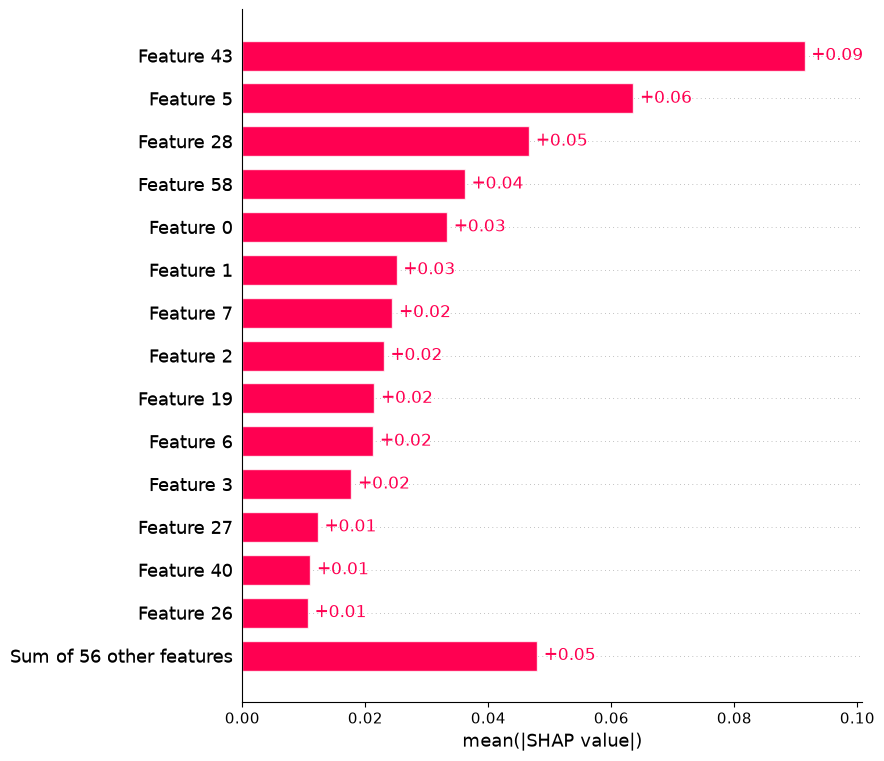

In [132]:
shap.plots.bar(
    shap_values[:, :, 1],
    max_display=15
)

In [133]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Display top 15 SHAP features with their actual names
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_shap": np.abs(shap_values.values[:, :, 1]).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "mean_shap",
    ascending=False
)

display(shap_importance.head(15))

,feature,mean_shap
43,cat__meta.system.service_Unknown,0.091435
5,num__sp,0.063594
28,cat__tls.scs_C030,0.046652
58,cat__meta.system.service_microsoft_core,0.036201
0,num__bs,0.033312
1,num__ps,0.025102
7,num__td,0.024408
2,num__br,0.023013
19,cat__tls.scs_1302,0.021482
6,num__ts,0.021304


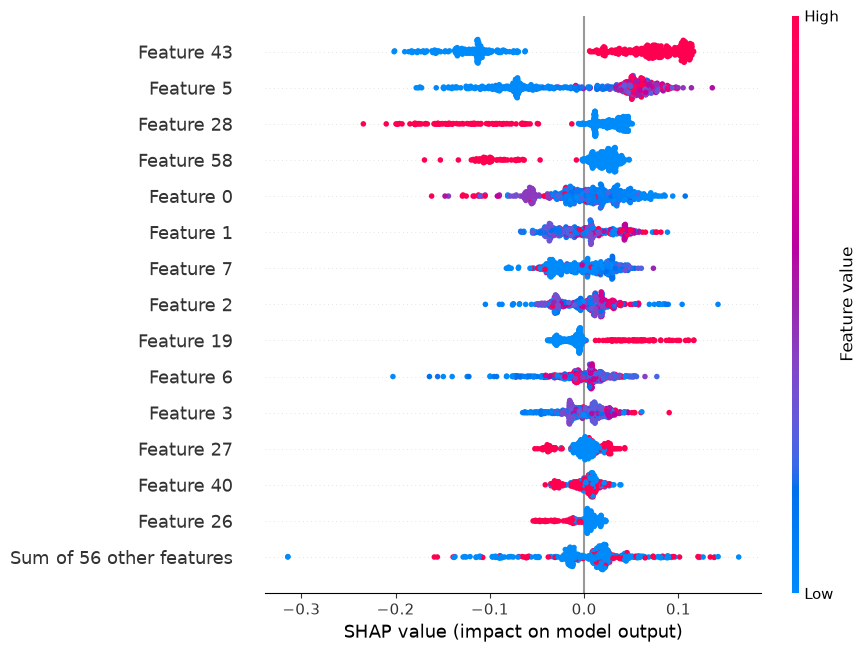

In [134]:
shap.plots.beeswarm(
    shap_values[:, :, 1],
    max_display=15
)

In [135]:
shap.plots.bar(
    shap_values[:, :, 1],
    max_display=15,
    show=False
)

plt.savefig(
    "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

In [137]:
import os

print(os.listdir(r"D:\Projects\VPN_Threat_Detection\models"))

['rf_sg_model.joblib']


In [138]:
import os

for root, dirs, files in os.walk(r"D:\Projects\VPN_Threat_Detection"):
    for file in files:
        if file.endswith(".joblib"):
            print(os.path.join(root, file))

D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib


In [139]:
%whos

Variable                          Type                      Data/Info
---------------------------------------------------------------------
ColumnTransformer                 ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay            type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_DIR                          WindowsPath               D:\college docs\Final Yea<...>Threat_Detection\Datasets
GroupShuffleSplit                 ABCMeta                   <class 'sklearn.model_sel<...>split.GroupShuffleSplit'>
MALWARE_DATA                      str                       D:\college docs\Final Yea<...>\Datasets\malware.parquet
OneHotEncoder                     type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
PROCESSED_DATA_DIR                WindowsPath               D:\Projects\VPN_Threat_Detection\data\processed
PROJECT_DIR                       WindowsPath           

In [140]:
[name for name in globals()
 if any(word in name.lower()
        for word in ["vpn", "classifier", "model", "clf"])]

['VPN_DATA',
 'vpn_features',
 'RandomForestClassifier',
 'rf_model',
 'classifier',
 'rf_grouped_model',
 'rf_sg_model',
 'rf_classifier',
 'rf_no_service_model',
 'model_path',
 'saved_model']

In [141]:
for name in [
    "rf_model",
    "classifier",
    "rf_grouped_model",
    "rf_sg_model",
    "rf_classifier",
    "rf_no_service_model"
]:
    obj = globals()[name]
    print(f"\n{name}: {type(obj).__name__}")

    if hasattr(obj, "n_estimators"):
        print("Trees:", obj.n_estimators)

    if hasattr(obj, "feature_names_in_"):
        print("Features:", len(obj.feature_names_in_))


rf_model: Pipeline
Features: 13

classifier: RandomForestClassifier
Trees: 30

rf_grouped_model: Pipeline
Features: 13

rf_sg_model: Pipeline
Features: 13

rf_classifier: RandomForestClassifier
Trees: 30

rf_no_service_model: Pipeline
Features: 12


In [142]:
print("VPN classifier:")
print(rf_grouped_model)

print("\nExpected input features:")
print(rf_grouped_model.feature_names_in_)

print("\nClasses:")
print(rf_grouped_model.classes_)

VPN classifier:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['bs', 'ps', 'br', 'pr', 'dp',
                                                   'sp', 'ts', 'td']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                              

In [143]:
print("VPN dataset columns:")
print(vpn_features.columns.tolist())

print("\nVPN model:")
print(type(rf_model).__name__)

print("\nVPN model feature names:")
print(rf_model.feature_names_in_)

VPN dataset columns:
['protocol', 'src_port', 'dst_port', 'total_packets', 'total_bytes', 'positive_bytes', 'negative_bytes', 'mean_packet_size', 'std_packet_size', 'duration', 'mean_inter_arrival', 'std_inter_arrival', 'category', 'application', 'is_vpn']

VPN model:
Pipeline

VPN model feature names:
['bs' 'ps' 'br' 'pr' 'dp' 'sp' 'ts' 'td' 'tls.cver' 'tls.sver' 'tls.scs'
 'meta.system.os' 'meta.system.service']


In [144]:
for name in ["vpn_features", "rf_model", "classifier",
             "rf_grouped_model", "rf_classifier"]:

    obj = globals()[name]

    print(f"\n{name}")

    if hasattr(obj, "feature_names_in_"):
        print(obj.feature_names_in_)

    if hasattr(obj, "named_steps"):
        print("Pipeline steps:", list(obj.named_steps.keys()))


vpn_features

rf_model
['bs' 'ps' 'br' 'pr' 'dp' 'sp' 'ts' 'td' 'tls.cver' 'tls.sver' 'tls.scs'
 'meta.system.os' 'meta.system.service']
Pipeline steps: ['preprocessor', 'classifier']

classifier

rf_grouped_model
['bs' 'ps' 'br' 'pr' 'dp' 'sp' 'ts' 'td' 'tls.cver' 'tls.sver' 'tls.scs'
 'meta.system.os' 'meta.system.service']
Pipeline steps: ['preprocessor', 'classifier']

rf_classifier


In [145]:
for name in ["vpn_features", "rf_model", "rf_grouped_model"]:
    print(name, type(globals()[name]))

vpn_features <class 'pandas.DataFrame'>
rf_model <class 'sklearn.pipeline.Pipeline'>
rf_grouped_model <class 'sklearn.pipeline.Pipeline'>


In [146]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Dedicated VPN dataset variables
X_vpn = vpn_features.drop(
    columns=["category", "application", "is_vpn"]
)

y_vpn = vpn_features["is_vpn"]

# Split VPN data
X_vpn_train, X_vpn_test, y_vpn_train, y_vpn_test = train_test_split(
    X_vpn,
    y_vpn,
    test_size=0.20,
    random_state=42,
    stratify=y_vpn
)

# Preprocessing
vpn_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"),
         X_vpn.select_dtypes(include="number").columns.tolist()),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["protocol"])
    ]
)

# VPN classifier
vpn_model = Pipeline(
    steps=[
        ("preprocessor", vpn_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train
vpn_model.fit(X_vpn_train, y_vpn_train)

# Evaluate
vpn_pred = vpn_model.predict(X_vpn_test)

print("VPN model trained!")
print("Accuracy:", accuracy_score(y_vpn_test, vpn_pred))
print(classification_report(
    y_vpn_test,
    vpn_pred,
    target_names=["Non-VPN", "VPN"]
))

VPN model trained!
Accuracy: 0.9925398440149203
              precision    recall  f1-score   support

     Non-VPN       1.00      0.99      1.00     10039
         VPN       0.96      0.99      0.98      1757

    accuracy                           0.99     11796
   macro avg       0.98      0.99      0.99     11796
weighted avg       0.99      0.99      0.99     11796



In [147]:
from pathlib import Path
import joblib

model_dir = Path(r"D:\Projects\VPN_Threat_Detection\models")
model_dir.mkdir(parents=True, exist_ok=True)

vpn_model_path = model_dir / "vpn_classifier.joblib"

joblib.dump(vpn_model, vpn_model_path)

print("VPN model saved:", vpn_model_path)

VPN model saved: D:\Projects\VPN_Threat_Detection\models\vpn_classifier.joblib


In [148]:
import joblib

vpn_model = joblib.load(
    r"D:\Projects\VPN_Threat_Detection\models\vpn_classifier.joblib"
)

malware_model = joblib.load(
    r"D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib"
)

print("VPN model:", type(vpn_model).__name__)
print("Malware model:", type(malware_model).__name__)

print("VPN classes:",
      vpn_model.named_steps["classifier"].classes_)

print("Malware classes:",
      malware_model.named_steps["classifier"].classes_)

VPN model: Pipeline
Malware model: Pipeline
VPN classes: [0 1]
Malware classes: [0 1]


In [149]:

def detect_traffic(vpn_record, malware_record, malware_threshold=0.6):

    # VPN prediction
    vpn_prediction = vpn_model.predict(vpn_record)[0]
    vpn_probability = vpn_model.predict_proba(vpn_record)[0][1]

    # Malware prediction
    malware_probability = malware_model.predict_proba(malware_record)[0][1]
    malware_prediction = int(malware_probability >= malware_threshold)

    # Combined result
    result = {
        "vpn_status": "VPN" if vpn_prediction == 1 else "Non-VPN",
        "vpn_probability": round(float(vpn_probability), 4),
        "malware_status": "Malicious" if malware_prediction == 1 else "Benign",
        "malware_probability": round(float(malware_probability), 4)
    }

    return result


In [150]:

# One VPN test sample
vpn_record = X_vpn_test.iloc[[0]]

# One malware test sample
malware_record = X_test.iloc[[0]]

# Combined prediction
result = detect_traffic(vpn_record, malware_record)

print(result)


{'vpn_status': 'Non-VPN', 'vpn_probability': 0.0, 'malware_status': 'Malicious', 'malware_probability': 0.929}


In [151]:
print("Actual VPN label:",
      y_vpn_test.iloc[0])

print("Predicted VPN label:",
      vpn_model.predict(vpn_record)[0])

print("Actual Malware label:",
      y_test.iloc[0])

print("Predicted Malware label:",
      malware_model.predict(malware_record)[0])

Actual VPN label: 0
Predicted VPN label: 0
Actual Malware label: 1
Predicted Malware label: 1


In [153]:
import os

for root, dirs, files in os.walk("D:\\"):
    dirs[:] = [d for d in dirs if d not in ["venv", "node_modules", "$Recycle.Bin"]]

    for file in files:
        if file in ["vpn_classifier.joblib", "rf_sg_model.joblib"]:
            print(os.path.join(root, file))

D:\Projects\VPN_Threat_Detection\models\rf_sg_model.joblib
D:\Projects\VPN_Threat_Detection\models\vpn_classifier.joblib


In [154]:
import os
import shutil

source = r"D:\Projects\VPN_Threat_Detection\models"
destination = r"D:\college docs\Final Year Project\VPN_Threat_Detection\models"

os.makedirs(destination, exist_ok=True)

for file in ["rf_sg_model.joblib", "vpn_classifier.joblib"]:
    shutil.copy2(
        os.path.join(source, file),
        os.path.join(destination, file)
    )

print("Models copied successfully!")


Models copied successfully!


In [155]:

import os

folders = {
    "MAIN": r"D:\college docs\Final Year Project\VPN_Threat_Detection",
    "SECONDARY": r"D:\Projects\VPN_Threat_Detection"
}

for name, path in folders.items():
    print(f"\n{'='*60}")
    print(name, ":", path)
    print("="*60)

    if not os.path.exists(path):
        print("Folder not found!")
        continue

    for root, dirs, files in os.walk(path):
        dirs[:] = [d for d in dirs if d not in {"venv", ".git", "__pycache__"}]

        relative = os.path.relpath(root, path)
        print(f"\n[{relative}]")

        for file in files:
            size_mb = os.path.getsize(os.path.join(root, file)) / (1024**2)
            print(f"  {file} ({size_mb:.2f} MB)")



MAIN : D:\college docs\Final Year Project\VPN_Threat_Detection

[.]
  .gitignore (0.00 MB)
  process.ipynb (0.86 MB)

[Datasets]

[Datasets\encrypted_vpn_dataset]

[Datasets\encrypted_vpn_dataset\Non VPN]
  mail.json (0.88 MB)
  meet.json (10.04 MB)
  non_streaming.json (3880.16 MB)
  ssh.json (2.81 MB)
  streaming.json (467.14 MB)

[Datasets\encrypted_vpn_dataset\VPN]

[Datasets\encrypted_vpn_dataset\VPN\L2TP]
  mail.json (0.01 MB)
  meet.json (5.41 MB)
  non_streaming.json (1485.53 MB)
  ssh.json (0.03 MB)
  streaming.json (200.26 MB)

[Datasets\encrypted_vpn_dataset\VPN\L2TP IPsec]
  mail.json (0.21 MB)
  meet.json (15.66 MB)
  non_streaming.json (2352.70 MB)
  ssh.json (0.04 MB)
  streaming.json (235.32 MB)

[Datasets\encrypted_vpn_dataset\VPN\OpenVPN]
  mail.json (6.94 MB)
  meet.json (14.88 MB)
  non_streaming.json (2007.58 MB)
  ssh.json (0.15 MB)
  streaming.json (312.16 MB)

[Datasets\encrypted_vpn_dataset\VPN\PPTP]
  mail.json (0.24 MB)
  meet.json (6.99 MB)
  non_streaming.

In [156]:

import os

path = r"D:\Projects\VPN_Threat_Detection"

for root, dirs, files in os.walk(path):
    dirs[:] = [d for d in dirs if d not in {"venv", ".git", "__pycache__"}]

    relative = os.path.relpath(root, path)
    print(f"\n[{relative}]")

    for file in files:
        full_path = os.path.join(root, file)
        size_mb = os.path.getsize(full_path) / (1024**2)
        print(f"{file} | {size_mb:.2f} MB")



[.]

[data]

[data\processed]
L2TP_mail.parquet | 0.01 MB
vpn_features.parquet | 3.28 MB

[data\processed\L2TP]
mail.parquet | 0.01 MB
meet.parquet | 0.01 MB
non_streaming.parquet | 0.08 MB
ssh.parquet | 0.01 MB
streaming.parquet | 0.01 MB

[data\processed\L2TP_IPsec]
mail.parquet | 0.01 MB
meet.parquet | 0.01 MB
non_streaming.parquet | 0.11 MB
ssh.parquet | 0.01 MB
streaming.parquet | 0.02 MB

[data\processed\Non_VPN]
mail.parquet | 0.01 MB
meet.parquet | 0.01 MB
non_streaming.parquet | 2.85 MB
ssh.parquet | 0.01 MB
streaming.parquet | 0.21 MB

[data\processed\OpenVPN]
mail.parquet | 0.01 MB
meet.parquet | 0.01 MB
non_streaming.parquet | 0.08 MB
ssh.parquet | 0.01 MB
streaming.parquet | 0.01 MB

[data\processed\PPTP]
mail.parquet | 0.01 MB
meet.parquet | 0.01 MB
non_streaming.parquet | 0.10 MB
ssh.parquet | 0.01 MB
streaming.parquet | 0.02 MB

[data\processed\SSTP]
mail.parquet | 0.01 MB
meet.parquet | 0.01 MB
non_streaming.parquet | 0.08 MB
ssh.parquet | 0.01 MB
streaming.parquet | 

In [157]:

import os
from collections import defaultdict

path = r"D:\Projects\VPN_Threat_Detection"

summary = defaultdict(lambda: {"count": 0, "size": 0, "files": []})

for root, dirs, files in os.walk(path):
    dirs[:] = [d for d in dirs if d not in {"venv", ".git", "__pycache__"}]

    for file in files:
        full = os.path.join(root, file)
        ext = os.path.splitext(file)[1].lower() or "[no extension]"
        rel = os.path.relpath(full, path)

        summary[ext]["count"] += 1
        summary[ext]["size"] += os.path.getsize(full)
        summary[ext]["files"].append(rel)

for ext, info in sorted(summary.items()):
    print(f"\n{ext}: {info['count']} files | {info['size']/1024**2:.2f} MB")
    if ext in [".py", ".ipynb", ".joblib", ".md", ".txt"]:
        for f in info["files"]:
            print("  ", f)



.joblib: 2 files | 17.59 MB
   models\rf_sg_model.joblib
   models\vpn_classifier.joblib

.parquet: 37 files | 7.17 MB


In [158]:

import os
import shutil

source = r"D:\Projects\VPN_Threat_Detection\data\processed"
destination = r"D:\college docs\Final Year Project\VPN_Threat_Detection\data\processed"

if os.path.exists(source):
    shutil.copytree(source, destination, dirs_exist_ok=True)
    print("Processed datasets copied successfully!")
else:
    print("Source folder not found!")


Processed datasets copied successfully!


In [159]:

import os

main = r"D:\college docs\Final Year Project\VPN_Threat_Detection"

for folder in ["models", "data\processed"]:
    path = os.path.join(main, folder)
    print(f"\n{folder}:")
    if os.path.exists(path):
        for root, dirs, files in os.walk(path):
            for file in files:
                print(" ", os.path.relpath(os.path.join(root, file), main))
    else:
        print("Folder missing!")



models:
  models\rf_sg_model.joblib
  models\vpn_classifier.joblib

data\processed:
  data\processed\L2TP_mail.parquet
  data\processed\vpn_features.parquet
  data\processed\L2TP\mail.parquet
  data\processed\L2TP\meet.parquet
  data\processed\L2TP\non_streaming.parquet
  data\processed\L2TP\ssh.parquet
  data\processed\L2TP\streaming.parquet
  data\processed\L2TP_IPsec\mail.parquet
  data\processed\L2TP_IPsec\meet.parquet
  data\processed\L2TP_IPsec\non_streaming.parquet
  data\processed\L2TP_IPsec\ssh.parquet
  data\processed\L2TP_IPsec\streaming.parquet
  data\processed\Non_VPN\mail.parquet
  data\processed\Non_VPN\meet.parquet
  data\processed\Non_VPN\non_streaming.parquet
  data\processed\Non_VPN\ssh.parquet
  data\processed\Non_VPN\streaming.parquet
  data\processed\OpenVPN\mail.parquet
  data\processed\OpenVPN\meet.parquet
  data\processed\OpenVPN\non_streaming.parquet
  data\processed\OpenVPN\ssh.parquet
  data\processed\OpenVPN\streaming.parquet
  data\processed\PPTP\mail.par

<>:5: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:5: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Sneha Karkoli\AppData\Local\Temp\ipykernel_13220\4109648613.py:5: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  for folder in ["models", "data\processed"]:


In [160]:
import subprocess

project = r"D:\college docs\Final Year Project\VPN_Threat_Detection"

result = subprocess.run(
    ["git", "status", "--short"],
    cwd=project,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

 M notebooks/01_data_processing.ipynb
?? notebooks/shap_global_importance.png
?? process.ipynb




In [161]:
project = r"D:\college docs\Final Year Project\VPN_Threat_Detection"

with open(project + r"\.gitignore", "r") as f:
    print(f.read())

@'
venv/
.venv/
__pycache__/
*.pyc
.ipynb_checkpoints/
data/raw/
data/processed/
Datasets/
*.parquet
*.json
models/*.joblib
.env
.DS_Store
Thumbs.db
'@ | Set-Content .gitignore
